# Домашнее задание 2. Вариант NLP: NER - детекция в тексте

**Дедлайн:** вс 22.11.2026, 23:59

В ДЗ2 вы выбираете **один** вариант: CV (детекция объектов на YOLO) или NLP (этот ноутбук). Номера задач и баллы в вариантах совпадают. NER (named entity recognition) - это детекция в тексте: найти спаны, т.е. непрерывные куски из слов, и для каждого предсказать тип сущности. Вы берете предобученный энкодер с Hugging Face Hub, находите свой датасет, приводите разметку к формату модели, дообучаете, считаете метрики и разбираете ошибки.

- Заполняйте места с `# ваш код` и ячейки «**Ответ:**». Сигнатуры функций и открытые тесты не меняйте, свои ячейки добавлять можно. Открытые тесты проверяют часть контракта, при проверке будут и другие входы
- В ответах опирайтесь на свои числа: наблюдение, объяснение, ограничение вывода. Обычно хватает 2-4 предложений. Отсутствие ожидаемого эффекта - нормальный результат, если эксперимент корректный и вы это обсудили
- Свой код обязателен в 1.2 (параметры по блокам), 2.2 (конвертация разметки + тесты), 3.1 (словарный бейзлайн), 5.1 (категоризация ошибок). Для обучения и стандартных метрик можно `transformers` (`Trainer` или свой цикл) и `seqeval`
- `FAST_MODE = True` - отладка на маленьком подмножестве, весь ноутбук не дольше 5 минут на T4. Финальный прогон - с `FAST_MODE = False`, ориентир до ~1 часа на T4. Бонусы включаются через `BONUS_TASKS`, выключенные бонусы пропускаются, даже если их ячейки пустые
- Запуск: Colab (T4) или Kaggle (GPU T4, ноутбук сам берет одну карту). Зависимости ставит первая ячейка, пины те же, что в `requirements_nlp.txt`. Укажите устройство в ячейке ниже, время обучения возвращает ваш `train_ner` (4.1)
- Только открытые модели и данные. Лицензию модели и датасета укажите в 1.1 и 2.1
- Можно документацию, материалы курса и код семинаров - укажите источник
- Сдача как в ДЗ1: PR в свой публичный GitHub-репозиторий, ссылка на него - в Google-форму (ссылку на форму дадим отдельно). В PR - ноутбук с outputs и `artifacts/metrics.json` (пишется в 5.3, перед бонусами). Датасет (`data/`), `runs/` и веса моделей не кладите, достаточно кода скачивания; файл доразметки из 6.1 - кладите
- Для полной сдачи: Restart & Run All с `FAST_MODE = False`, сохранить outputs. Если сдаете частичное решение, перечислите нерешенные задачи в ячейке ниже и приложите то, что получилось. Ошибки не скрывайте: баллы ставятся по задачам, одна ошибка не обнуляет остальные
- ДЗ индивидуальное

| раздел | задачи | баллы |
|---|---|---|
| 1. Модель | 1.1 модель и ревизия · 1.2 архитектура | 4 |
| 2. Данные | 2.1 датасет · 2.2 формат разметки | 4 |
| 3. Бейзлайн | 3.1 бейзлайн до дообучения | 2 |
| 4. Дообучение | 4.1 обучение · 4.2 метрики | 6 |
| 5. Анализ | 5.1 разбор ошибок · 5.2 абляция · 5.3 выводы | 4 |
| 6*. Бонусы | 6.1 доразметка · 6.2 другая модель · 6.3 сдвиг · 6.4 экспорт и скорость · 6.5 пороги | до +4 из 5.5 |
| итого | | 20 + 4 |

Соответствие с CV-вариантом - задачи те же, меняется «геометрия»: вместо прямоугольника на картинке - отрезок из слов в предложении.

| CV (детекция на картинке) | NLP (NER в тексте) |
|---|---|
| бокс | спан: (начало, конец, тип) в индексах слов |
| класс объекта | тип сущности (PER, ORG, LOC, ...) |
| фон | тег `O` |
| VOC / COCO -> YOLO-формат | слова и спаны -> BIO-теги под сабворды токенизатора |
| backbone -> neck -> head | эмбеддинги -> слои энкодера -> голова token classification |
| mAP по IoU | F1 по сущностям (`seqeval`, спан засчитывается при точном совпадении границ и типа) |
| ошибка локализации (IoU 0.1-0.5) | ошибка границы спана (тип верный, спаны пересекаются) |
| ошибка класса | ошибка типа |
| пропуск / лишний бокс | пропуск / лишний спан |
| порог conf | порог уверенности спана |

Внутренности трансформера (attention, устройство слоя энкодера) - тема ДЗ3. Здесь энкодер рассматривается на уровне блоков.

Примерный план: первая неделя - разделы 1-3 (модель, датасет, разметка, бейзлайн), вторая - обучение, метрики, разбор ошибок, абляция и финальный прогон.

**Сведения о сдаче.** Укажите устройство (Colab T4 / Kaggle / свое), выбранные модель и датасет (ссылка и лицензия), бонусы, внешние источники и нерешенные задачи (если есть).

**Ответ:**

Вариант NLP, Colab с GPU Tesla T4. Основная модель — [cointegrated/rubert-tiny2](https://huggingface.co/cointegrated/rubert-tiny2), лицензия MIT. Датасет — [MedTerm из RuClinNER](https://huggingface.co/datasets/medlinx/RuClinNER), лицензия CC BY-NC-SA 4.0. В бонусе 6.2 используется [ai-forever/ruBert-base](https://huggingface.co/ai-forever/ruBert-base), лицензия Apache 2.0.

Выполнены основная часть и бонусы 6.2–6.5. Бонус 6.1 пропущен.

In [1]:
# Зависимости (пины те же, что в requirements_nlp.txt). Запускайте эту ячейку первой, тогда перезапуск сессии не нужен
# Безвредный шум: строки ERROR от pip про bigframes / cudf / pyarrow на Kaggle и предупреждение про HF_TOKEN ниже (токен не нужен)
# Локально: сначала torch под свою платформу (https://pytorch.org/get-started/locally/)
%pip install -q "torch>=2.4" "transformers==5.22.1" "datasets==5.1.0" "accelerate==1.15.0" "seqeval==1.2.2" numpy matplotlib

In [2]:
import os
os.environ.setdefault('CUDA_VISIBLE_DEVICES', '0')   # одна GPU: на Kaggle T4 x2 иначе Trainer включит DataParallel (медленнее и хуже)
import collections
import copy
import json
import math
import random
import re
import time
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import torch

import datasets
import transformers
from datasets import DatasetDict, load_dataset
from huggingface_hub import HfApi
from seqeval.metrics import classification_report, f1_score, precision_score, recall_score
from transformers import (AutoModelForTokenClassification, AutoTokenizer, DataCollatorForTokenClassification,
                          Trainer, TrainingArguments)

transformers.logging.set_verbosity_error()
plt.rcParams['figure.dpi'] = 100
plt.rcParams['font.size'] = 11

print(f'torch {torch.__version__}, transformers {transformers.__version__}, datasets {datasets.__version__}')
print(f'CUDA available: {torch.cuda.is_available()}')

torch 2.14.1+cu130, transformers 5.22.1, datasets 5.1.0
CUDA available: True


In [3]:
def get_device():
    if torch.cuda.is_available():
        return torch.device('cuda')
    if torch.backends.mps.is_available():
        return torch.device('mps')
    return torch.device('cpu')


def set_seed(seed=0):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    transformers.set_seed(seed)


device = get_device()
DEVICE_NAME = torch.cuda.get_device_name(0) if device.type == 'cuda' else device.type
set_seed(0)
print(device, DEVICE_NAME)

cuda Tesla T4


In [4]:
FAST_MODE = False   # True - отладка, False - финальный прогон
BONUS_TASKS = {'6.2', '6.3', '6.4', '6.5'}   # например {'6.3', '6.5'}; пустое множество отключает все бонусы
assert BONUS_TASKS <= {'6.1', '6.2', '6.3', '6.4', '6.5'}

SEED = 0
N_TRAIN = 2000 if FAST_MODE else None   # None - весь train
N_EVAL = 500 if FAST_MODE else None     # подмножество validation и test в FAST_MODE
EPOCHS = 1 if FAST_MODE else 6
MAX_LENGTH = 256                        # длина в сабвордах, длиннее - обрезается
ARTIFACTS = Path('artifacts')
ARTIFACTS.mkdir(exist_ok=True)
RUN_TIMES = {}

---
# 1. Модель

## 1.1 Модель и ревизия (1.5 балла)

Выберите предобученный энкодер на Hugging Face Hub, подходящий под язык и домен вашего датасета. Модель на Hub - это git-репозиторий: владелец может перезалить веса, токенизатор или конфиг, и `main` начнет указывать на другую версию. Поэтому зафиксируйте `revision` - полный commit hash (40 символов). Его видно во вкладке «Files and versions» -> «History» или через `HfApi().model_info(MODEL_ID).sha`.

Ориентиры для выбора (не исчерпывающий список):
- русский: `cointegrated/rubert-tiny2` (29M параметров, быстрый), `DeepPavlov/rubert-base-cased` (~180M)
- многоязычные: `FacebookAI/xlm-roberta-base` (~280M), `google-bert/bert-base-multilingual-cased` (~180M), `distilbert/distilbert-base-multilingual-cased`
- английский: `google-bert/bert-base-cased`, `FacebookAI/roberta-base` (в 1.1 задайте `TOKENIZER_KWARGS = {'add_prefix_space': True}`), `microsoft/deberta-v3-small`
- биомедицина: `dmis-lab/biobert-base-cased-v1.2`

Нужен fast-токенизатор: `word_ids()`, без которого не выровнять метки по сабвордам, есть только у него. На T4 модель до ~300M параметров дообучается на датасете в десятки тысяч предложений за минуты - десятки минут.

Нужен базовый энкодер, а не модель, уже дообученная на NER: с ней 3.1 и 4.1 теряют смысл.

In [5]:
print(HfApi().model_info('cointegrated/rubert-tiny2').sha)

e8ed3b0c8bbf4fb6984c3de043bf7d2f4e5969ae


In [6]:
MODEL_ID = 'cointegrated/rubert-tiny2'   # ваш код: id модели на Hugging Face Hub
REVISION = 'e8ed3b0c8bbf4fb6984c3de043bf7d2f4e5969ae'   # ваш код: полный commit hash (40 символов)
TOKENIZER_KWARGS = {}   # для roberta-base: {'add_prefix_space': True}

In [7]:
assert MODEL_ID, 'укажите MODEL_ID'
assert re.fullmatch(r'[0-9a-f]{40}', REVISION or ''), 'REVISION - полный commit hash из 40 символов, а не main и не тег'
info = HfApi().model_info(MODEL_ID, revision=REVISION, files_metadata=True)
card = info.card_data.to_dict() if info.card_data else {}
weights = {s.rfilename: f'{s.size / 2**20:.0f} MB' for s in info.siblings if s.rfilename.endswith(('.safetensors', '.bin'))}
print(f'model:    {MODEL_ID}\nrevision: {info.sha}\nlicense:  {card.get("license")}\nlanguage: {card.get("language")}')
print(f'updated:  {info.last_modified}\nweights:  {weights}')

tokenizer = AutoTokenizer.from_pretrained(MODEL_ID, revision=REVISION, **TOKENIZER_KWARGS)
assert tokenizer.is_fast, 'нужен fast-токенизатор: word_ids() есть только у него'
print(type(tokenizer).__name__, 'vocab size', tokenizer.vocab_size)
print(tokenizer.tokenize('Петр Ильич Чайковский родился в Воткинске'))

model:    cointegrated/rubert-tiny2
revision: e8ed3b0c8bbf4fb6984c3de043bf7d2f4e5969ae
license:  mit
language: ['ru']
updated:  2025-12-30 08:33:24+00:00
weights:  {'model.safetensors': '112 MB', 'pytorch_model.bin': '112 MB'}
BertTokenizer vocab size 83828
['Петр', 'Ильич', 'Чайк', '##овский', 'родился', 'в', 'Вот', '##кинс', '##ке']


**Вопрос.** Почему вы выбрали эту модель: язык и данные предобучения, размер и скорость, ожидаемое качество на NER, лицензия? Сравните с 1-2 альтернативами из списка выше: размер, язык, скорость, качество по карточке. Что может сломаться в вашем ноутбуке через полгода, если не фиксировать `revision`?

**Ответ:**

Выбрана **cointegrated/rubert-tiny2**: она работает с русским языком и сравнительно небольшая (около 29.1 млн параметров). Это удобно для обучения и повторных экспериментов на T4. Лицензия модели - MIT. По описанию автора, при обучении использовались восстановление скрытых токенов, определение отношений между текстами и приближение векторов модели LaBSE. Полный список обучающих текстов в карточке не указан. Эти навыки могут помочь в NER, а качество будет проверено после дообучения.

Альтернатива **DeepPavlov/rubert-base-cased** тоже работает с русским языком и обучена на русской Википедии и новостях. В ней около 180 млн параметров, поэтому она требует больше памяти и, скорее всего, будет медленнее. Большая модель может лучше справляться со сложными примерами, но её размер не гарантирует лучшего качества NER. Сопоставимых результатов на выбранном датасете в карточках нет.

Зафиксирована версия **e8ed3b0c8bbf4fb6984c3de043bf7d2f4e5969ae**, чтобы при следующих запусках загружались те же файлы. Если оставить main, обновление весов, настроек или токенизатора может изменить разбиение текста и результаты либо нарушить работу кода. Для повторения результатов тоже важны версии библиотек и настройки обучения.

## 1.2 Архитектура (2.5 балла)

Энкодер для token classification на уровне блоков:

1. **эмбеддинги** - сабворд -> вектор размера hidden (таблица `vocab_size x hidden`) + позиционные эмбеддинги (у DeBERTa их нет, позиции учитываются в attention) и type-эмбеддинги (у BERT-подобных), LayerNorm, dropout. Выход `(B, T, H)`
2. **N слоев энкодера** - одинаковые по форме блоки `(B, T, H) -> (B, T, H)`, в которых токены обмениваются информацией друг с другом. Устройство слоя (attention, FFN) - ДЗ3
3. **голова token classification** - dropout + `Linear(H, K)` к каждому токену независимо, K - число BIO-тегов. Выход - logits `(B, T, K)`
4. **сборка спанов** - argmax по тегам на первом сабворде каждого слова, затем BIO -> спаны (это уже не нейросеть, а ваш код из 2.2)

Ниже модель создается с головой на `N_DEMO_LABELS = 7` тегов (O + B/I для трех типов), под ваш датасет голову пересоздает `make_model` (3.1, 4.1).

1. Реализуйте `params_by_block(model)` - число параметров по блокам: `embeddings`, `encoder` (все слои), `head` (классификатор), `other` (все остальное: у BERT и RoBERTa для token classification здесь 0, у DeBERTa - `encoder.rel_embeddings` и общий `encoder.LayerNorm`) и `layers` - список по слоям энкодера. Сумма блоков должна совпасть с общим числом параметров
2. Прогоните dummy-вход `demo_texts` (батч из двух предложений, уже разбитых на слова) через токенизатор и модель с `output_hidden_states=True`, сохраните результат токенизатора в `enc`, выход модели в `out` и выведите формы: `input_ids`, `attention_mask`, все `hidden_states`, `logits`

In [8]:
N_DEMO_LABELS = 7
demo_model = AutoModelForTokenClassification.from_pretrained(MODEL_ID, revision=REVISION, num_labels=N_DEMO_LABELS)
cfg = demo_model.config
print({k: getattr(cfg, k, None) for k in ['model_type', 'vocab_size', 'hidden_size', 'num_hidden_layers',
                                          'num_attention_heads', 'intermediate_size', 'max_position_embeddings']})
for name, module in demo_model.named_children():
    print(f'{name:<12} {type(module).__name__}')

Loading weights:   0%|          | 0/53 [00:00<?, ?it/s]

{'model_type': 'bert', 'vocab_size': 83828, 'hidden_size': 312, 'num_hidden_layers': 3, 'num_attention_heads': 12, 'intermediate_size': 600, 'max_position_embeddings': 2048}
bert         BertModel
dropout      Dropout
classifier   Linear


In [9]:
def params_by_block(model):
    def count_params(module):
        return sum(p.numel() for p in module.parameters())

    base = model.base_model
    embeddings = count_params(base.embeddings)
    layers = [
        count_params(layer)
        for layer in base.encoder.layer
    ]
    encoder = sum(layers)
    head = count_params(model.classifier)
    total = count_params(model)
    other = total - embeddings - encoder - head

    return {
        'embeddings': embeddings,
        'encoder': encoder,
        'head': head,
        'other': other,
        'layers': layers,
    }

In [10]:
blocks = params_by_block(demo_model)
total = sum(p.numel() for p in demo_model.parameters())
assert sum(blocks[k] for k in ['embeddings', 'encoder', 'head', 'other']) == total
assert blocks['head'] == cfg.hidden_size * N_DEMO_LABELS + N_DEMO_LABELS
assert len(blocks['layers']) == cfg.num_hidden_layers and sum(blocks['layers']) == blocks['encoder'], \
    'encoder - сумма слоев, все вне слоев (например, rel_embeddings у DeBERTa) - в other'
assert blocks['embeddings'] >= cfg.vocab_size * cfg.hidden_size
for k in ['embeddings', 'encoder', 'head', 'other']:
    print(f'{k:<11}{blocks[k]:>13,}  {blocks[k] / total:6.1%}')
print(f'{"total":<11}{total:>13,}\nper layer: {blocks["layers"]}')

embeddings    26,794,560   92.1%
encoder        2,301,552    7.9%
head               2,191    0.0%
other                  0    0.0%
total         29,098,303
per layer: [767184, 767184, 767184]


In [11]:
demo_texts = [
    ['Петр', 'Чайковский', 'родился', 'в', 'Воткинске', '.'],
    ['ITMO', 'University', 'is', 'in', 'Saint', 'Petersburg']
]

enc = tokenizer(
    demo_texts,
    is_split_into_words=True,
    padding=True,
    truncation=True,
    max_length=MAX_LENGTH,
    return_tensors='pt'
)
enc = enc.to(device)
demo_model = demo_model.to(device)
demo_model.eval()
with torch.inference_mode():
    out = demo_model(**enc, output_hidden_states=True)

print('input_ids:', tuple(enc['input_ids'].shape))
print('attention_mask:', tuple(enc['attention_mask'].shape))

for i, hidden in enumerate(out.hidden_states):
    print(f'hidden_states[{i}]:', tuple(hidden.shape))

print('logits:', tuple(out.logits.shape))

input_ids: (2, 11)
attention_mask: (2, 11)
hidden_states[0]: (2, 11, 312)
hidden_states[1]: (2, 11, 312)
hidden_states[2]: (2, 11, 312)
hidden_states[3]: (2, 11, 312)
logits: (2, 11, 7)


In [12]:
B, T = enc['input_ids'].shape
assert B == 2 and out.logits.shape == (B, T, N_DEMO_LABELS)
assert len(out.hidden_states) == cfg.num_hidden_layers + 1
assert all(h.shape == (B, T, cfg.hidden_size) for h in out.hidden_states)

# скорость прямого прохода: батч 32 предложения x 62 слова (сколько это сабвордов - см. вывод)
x = {k: v.to(device) for k, v in tokenizer([['слово'] * 62] * 32, is_split_into_words=True, return_tensors='pt').items()}
demo_model.to(device).eval()
with torch.inference_mode():
    demo_model(**x)
    if device.type == 'cuda':
        torch.cuda.synchronize()
    start = time.perf_counter()
    for _ in range(5):
        demo_model(**x)
    if device.type == 'cuda':
        torch.cuda.synchronize()
print(f'forward 32 x {x["input_ids"].shape[1]}: {(time.perf_counter() - start) / 5 * 1000:.1f} ms на {DEVICE_NAME}')
demo_model = demo_model.cpu()

forward 32 x 64: 6.5 ms на Tesla T4


**Вопрос.** Опишите путь входа по блокам с формами тензоров из вашего вывода. Какой блок содержит больше всего параметров и почему? В каком блоке токены обмениваются информацией, а где каждый токен обрабатывается независимо? Почему `T` в logits больше числа слов?

**Ответ:**

После токенизации **input_ids** и **attention_mask** имеют форму **(2, 11)** (в батче 2 предложения, длина последовательностей — 11 позиций). Блок эмбеддингов выдаёт тензор **(2, 11, 312)**, и каждый из 3 слоёв энкодера сохраняет эту форму, меняя значения векторов. Поэтому получены 4 **hidden_states** (после эмбеддингов и после каждого слоя). Классификатор преобразует вектор из 312 чисел в 7 оценок меток, поэтому форма **logits** — **(2, 11, 7)**.

Больше всего параметров находится в блоке эмбеддингов — 26 794 560 (92.1% от общего числа). Основная причина — большая таблица (для каждого из 83 828 токенов хранится вектор длины 312). В слоях энкодера находится 2 301 552 параметра, в классификаторе — 2 191, всего — 29 098 303.

Токены обмениваются информацией через attention в слоях энкодера. В блоке эмбеддингов каждая позиция обрабатывается отдельно, а классификатор применяет одно и то же преобразование к каждому выходному вектору независимо. При этом вектор уже содержит информацию о контексте. Длина **T** больше числа исходных слов, т.к слова могут разбиваться на несколько сабвордов и добавляются служебные токены. Более короткие последовательности в батче дополняются padding-токенами.

Среднее время прямого прохода батча из 32 последовательностей по 64 токена составило 6.5 мс на Tesla T4.

---
# 2. Данные

## 2.1 Датасет (1.5 балла)

Найдите датасет для NER на Hugging Face Hub или в другом открытом источнике, подходящий под вашу модель по языку. Опишите источник, лицензию, как размечали, типы сущностей, размер и сплиты; посчитайте статистику: число сущностей каждого типа по сплитам, распределение длин спанов (в словах), длины предложений.

**Нельзя брать WikiANN ru** (`unimelb-nlp/wikiann`, конфиг `ru`) - на нем ниже показан пример формата. Другие языки WikiANN брать можно.

Подсказки - датасеты, которые на момент выдачи загружаются текущей библиотекой `datasets` (проверено 31.10.2026, `datasets` 5.1). Библиотека больше не исполняет loading-скрипты, поэтому часть датасетов грузится из служебной ветки с parquet-версией - так, как написано в списке:

Русский:
- `Babelscape/wikineural` - WikiNEuRal, PER / ORG / LOC / MISC, 9 языков; для русского сплиты `train_ru`, `val_ru`, `test_ru`; CC BY-NC-SA 4.0
- `Babelscape/multinerd` - MultiNERD, 15 типов, 10 языков, колонка `lang` - отфильтруйте `ru`; CC BY-NC-SA 4.0
- `load_dataset('RCC-MSU/collection3', revision='refs/convert/parquet')` - Collection3, новости, PER / ORG / LOC, уже `tokens` + `ner_tags`
- `undefinedhorizons/nerus_lenta` - Nerus: новости Lenta.ru с автоматической разметкой PER / LOC / ORG, только `train` и очень большой - возьмите подмножество и сами отделите validation и test
- `gusevski/factrueval2016` - FactRuEval-2016, новости; вся разметка в одной вложенной колонке `data` - разобрать в предложения, слова и BIO
- `load_dataset('iluvvatar/RuNNE', revision='refs/convert/parquet')` и то же для `iluvvatar/NEREL` - новости, 29 типов, вложенные сущности, спаны по символам в тексте. Нужны разбиение на предложения и слова (целый текст длиннее `MAX_LENGTH = 128` сабвордов, хвост обрежется), BIO и правило для вложенных (например, оставить только внешние) - самая содержательная конвертация из списка

Другие языки:
- `unimelb-nlp/wikiann` - WikiANN, 176 языков (любой, кроме `ru`), PER / ORG / LOC
- `lhoestq/conll2003`, `tomaarsen/conll2003` или `load_dataset('eriktks/conll2003', revision='refs/convert/parquet')` - CoNLL-2003, английский, PER / ORG / LOC / MISC
- `DFKI-SLT/few-nerd`, конфиг `supervised` - Few-NERD, английский, 8 крупных и 66 мелких типов; теги в IO-схеме (без `B-` и `I-`) - переведите в BIO; CC BY-SA 4.0
- `load_dataset('tner/wnut2017', revision='refs/convert/parquet')` - WNUT-17, соцсети, редкие и новые сущности; имена тегов - в файле `dataset/label.json` репозитория

Биомедицина (английский):
- `load_dataset('ncbi/ncbi_disease', revision='refs/convert/parquet')` - NCBI-disease, один тип Disease
- `load_dataset('tner/bc5cdr', revision='refs/convert/parquet')` - BC5CDR, Chemical / Disease, теги в колонке `tags`: `{"O": 0, "B-Chemical": 1, "B-Disease": 2, "I-Disease": 3, "I-Chemical": 4}`

Если `load_dataset('<id>')` падает из-за loading-скрипта, берите ветку `revision='refs/convert/parquet'` (как в списке) или сырые файлы: `load_dataset('json', data_files='hf://datasets/<id>/<путь к файлу>')`. Датасеты из списка разрешены, лицензию укажите, как в карточке.

Если сплита validation или test нет, отделите их сами (`train_test_split` с фиксированным seed). Если датасет очень большой, возьмите подмножество и укажите это.

Контракт для остального ноутбука (после 2.2): `raw` - `DatasetDict` со сплитами `train`, `validation`, `test`, у каждого примера `tokens` (список слов) и `ner_tags` (список id тегов той же длины); `LABEL_NAMES` - список BIO-тегов, `LABEL_NAMES[i]` - тег с id `i`, тег `O` обязателен.

Если у `ner_tags` нет имен тегов (в `features` список чисел, а не `ClassLabel`; так у WikiNEuRal, MultiNERD и `lhoestq/conll2003`), составьте `LABEL_NAMES` вручную по карточке датасета. Например, у WikiNEuRal: `['O', 'B-PER', 'I-PER', 'B-ORG', 'I-ORG', 'B-LOC', 'I-LOC', 'B-MISC', 'I-MISC']`.

In [13]:
# пример формата на WikiANN ru (этот датасет брать нельзя)
example = load_dataset('unimelb-nlp/wikiann', 'ru', split='validation[:3]')
print(example)
print(example.features['ner_tags'].feature.names)
for ex in example:
    print(list(zip(ex['tokens'], ex['ner_tags'])), ex['spans'])

Dataset({
    features: ['tokens', 'ner_tags', 'langs', 'spans'],
    num_rows: 3
})
['O', 'B-PER', 'I-PER', 'B-ORG', 'I-ORG', 'B-LOC', 'I-LOC']
[('Отличился', 0), ('во', 0), ('время', 0), ('боёв', 0), ('в', 0), ('Германии', 5), ('.', 0)] ['LOC: Германии']
[('1920—1922', 0), ('—', 0), ('техник', 0), ('военно-гидротехнического', 0), ('отряда', 0), ('(', 0), ('Чернигов', 5), (')', 0), (',', 0)] ['LOC: Чернигов']
[('Нагибин', 1), (',', 2), ('Владимир', 2), ('Владимирович', 2)] ['PER: Нагибин , Владимир Владимирович']


In [14]:
DATASET_ID, DATASET_CONFIG = 'medlinx/RuClinNER','medterm'   # ваш код
raw = load_dataset(DATASET_ID, DATASET_CONFIG)           # ваш код: загрузите датасет
LABEL_NAMES = [   # ваш код: список BIO-тегов, LABEL_NAMES[i] - тег с id i
               'O',
    'B-SYMPTOM', 'I-SYMPTOM',
    'B-DISEASE', 'I-DISEASE',
    'B-RISK', 'I-RISK',
]

split           texts    SYMPTOM    DISEASE     RISK
train            2439       6724        560      752
validation        610       1673        118      207
test             1425       2255        160      133

train:
  Длина текста, слов: среднее = 11.27, медиана = 9.0, максимум = 122
  Длина сущности, слов: среднее = 2.10, медиана = 2.0, максимум = 11

validation:
  Длина текста, слов: среднее = 11.17, медиана = 9.0, максимум = 133
  Длина сущности, слов: среднее = 2.05, медиана = 2.0, максимум = 11

test:
  Длина текста, слов: среднее = 9.55, медиана = 8.0, максимум = 108
  Длина сущности, слов: среднее = 2.15, медиана = 2.0, максимум = 10


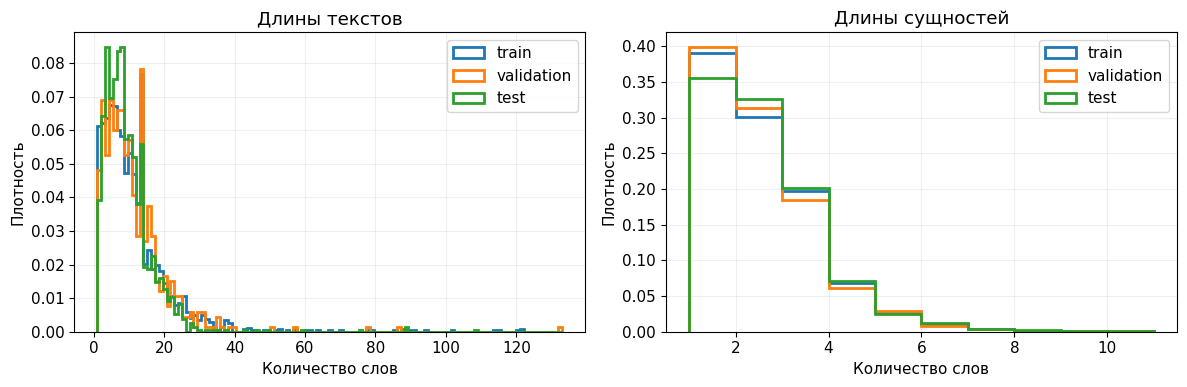

In [15]:
from collections import Counter
import re

if 'validation' not in raw:
    split = raw['train'].train_test_split(
        test_size=0.2,
        seed=SEED,
    )

    raw = DatasetDict({
        'train': split['train'],
        'validation': split['test'],
        'test': raw['test'],
    })

def count_words(text):
    return len(re.findall(r'\w+(?:[-’\']\w+)*', text))


entity_counts = {}
span_lengths = {}
text_lengths = {}
for split_name, dataset in raw.items():
    entity_counts[split_name] = Counter()
    span_lengths[split_name] = []
    text_lengths[split_name] = []
    for example in dataset:
        text = example['text']
        text_lengths[split_name].append(count_words(text))
        for entity in example['entities']:
            label = entity['label']
            span_text = text[entity['start']:entity['end']]
            entity_counts[split_name][label] += 1
            span_lengths[split_name].append(count_words(span_text))

print(f'{"split":<12}{"texts":>9}{"SYMPTOM":>11}{"DISEASE":>11}{"RISK":>9}')

for split_name, dataset in raw.items():
    counts = entity_counts[split_name]

    print(
        f'{split_name:<12}{len(dataset):>9}'
        f'{counts["SYMPTOM"]:>11}'
        f'{counts["DISEASE"]:>11}'
        f'{counts["RISK"]:>9}'
    )


for split_name in raw:
    print(f'\n{split_name}:')

    for name, values in [
        ('Длина текста', text_lengths[split_name]),
        ('Длина сущности', span_lengths[split_name]),
    ]:
        print(
            f'  {name}, слов: '
            f'среднее = {np.mean(values):.2f}, '
            f'медиана = {np.median(values):.1f}, '
            f'максимум = {max(values)}'
        )


fig, axes = plt.subplots(1, 2, figsize=(12, 4))

distributions = [
    (text_lengths, 'Длины текстов'),
    (span_lengths, 'Длины сущностей'),
]

for ax, (lengths, title) in zip(axes, distributions):
    all_lengths = [
        length
        for values in lengths.values()
        for length in values
    ]
    bins = np.histogram_bin_edges(all_lengths, bins='auto')

    for split_name, values in lengths.items():
        ax.hist(
            values,
            bins=bins,
            density=True,
            histtype='step',
            linewidth=2,
            label=split_name,
        )

    ax.set_title(title)
    ax.set_xlabel('Количество слов')
    ax.set_ylabel('Плотность')
    ax.legend()
    ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

**Вопрос.** Откуда датасет, под какой лицензией и как его размечали (вручную, автоматически, полуавтоматически)? Какие типы сущностей, сколько их по сплитам, какие типы редкие? Какие особенности данных (длина спанов, длина предложений, шум разметки) могут повлиять на обучение?

**Ответ:**

Использован MedTerm — часть датасета [RuClinNER](https://huggingface.co/datasets/medlinx/RuClinNER), опубликованного Medlinx под лицензией CC BY-NC-SA 4.0. Это короткие русскоязычные жалобы пациентов из сервиса проверки симптомов. По описанию авторов, разметка выполнялась вручную профильными экспертами по общей инструкции, а разногласия согласовывались.

Выделяются 3 типа сущностей: SYMPTOM — симптомы, DISEASE — заболевания, RISK — факторы риска. Из исходного train выделено 20% примеров для validation с фиксированным seed, исходный test сохранён.

| Сплит | Тексты | SYMPTOM | DISEASE | RISK |
|:---|---:|---:|---:|---:|
| train | 2439 | 6724 | 560 | 752 |
| validation | 610 | 1673 | 118 | 207 |
| test | 1425 | 2255 | 160 | 133 |

Во всех сплитах преобладают симптомы. Заболевания и факторы риска встречаются реже, поэтому качество по ним может быть ниже. Из-за дисбаланса важно оценивать не только общую F1, но и метрики отдельных типов.

Средняя длина текста составляет 11.27 / 11.17 / 9.55 слова для train / validation / test, медиана — 9 / 9 / 8 слов. Длина считается для целой записи с жалобой, которая может содержать несколько предложений. Средняя длина сущности равна 2.10 / 2.05 / 2.15 слова, медиана во всех сплитах — 2 слова. Распределения сосредоточены на коротких текстах и сущностях, но имеют хвост из более длинных примеров.

По описанию датасета, в жалобах встречаются опечатки, сокращения и разные формулировки одних симптомов. Это усложняет распознавание, а длинные примеры могут обрезаться при токенизации с MAX_LENGTH = 256, поскольку ограничение задано в сабвордах, а не в словах. Экспертная проверка уменьшает риск ошибок разметки.

## 2.2 Формат разметки (2.5 балла)

Модель предсказывает тег для каждого **сабворда**, а разметка дана по **словам** (или спанами по символам). Нужны две конвертации и тесты к ним.

1. `bio_to_spans(tags)` - BIO-теги слов -> список спанов `(start, end, type)`, `end` не включается. `B-X` начинает спан, `I-X` продолжает спан того же типа, иначе начинает новый (так делает `seqeval` в режиме по умолчанию), `O` закрывает спан. Тип может содержать дефис (`B-art-film` -> `art-film`)
2. `spans_to_bio(spans, n_words)` - обратно: спаны -> BIO-теги длины `n_words`
3. `align_labels(word_labels, word_ids, b_to_i=None)` - метки слов -> метки сабвордов. `word_ids` - выход `tokenizer(...).word_ids(i)`: номер слова для каждого сабворда, `None` у спецтокенов. По умолчанию метка слова ставится на его первый сабворд, спецтокены и продолжения слова получают `-100` (cross-entropy их игнорирует). Если передан словарь `b_to_i` (id тега `B-X` -> id тега `I-X`), метку получают все сабворды слова, у продолжений `B-X` заменяется на `I-X` - это вариант для абляции 5.2

Если ваш датасет не в формате «слова + BIO» (спаны по символам, IO-теги, CoNLL-текст), сначала приведите его к контракту из 2.1 и проверьте конвертацию на примерах глазами. Если датасет уже в BIO, сделайте обратную конвертацию: BIO -> спаны в JSON (`data/<split>_spans.jsonl`), прочитайте файл обратно, сконвертируйте в BIO и проверьте, что получилось то же самое (если в исходнике есть `I-X` без `B-X`, дословно не совпадет: сравните спаны и посчитайте такие предложения).

In [16]:
def bio_to_spans(tags):
    spans = []
    start, current_type = None, None
    for i, tag in enumerate(list(tags) + ['O']):
        if tag == 'O':
            prefix, entity_type = 'O', None
        else:
            prefix, entity_type = tag.split('-', 1)

            if prefix not in ('B', 'I') or not entity_type:
                raise ValueError(f'Некорректный BIO-тег: {tag}')
        if start is not None and (
            prefix != 'I' or entity_type != current_type
        ):
            spans.append((start, i, current_type))
            start, current_type = None, None
        if prefix != 'O' and start is None:
            start, current_type = i, entity_type

    return spans


def spans_to_bio(spans, n_words):
    if n_words < 0:
        raise ValueError('Число слов не может быть отрицательным')
    tags = ['O'] * n_words
    for start, end, entity_type in spans:
        if not 0 <= start < end <= n_words:
            raise ValueError(f'Некорректные границы: {(start, end)}')
        if any(tag != 'O' for tag in tags[start:end]):
            raise ValueError('Пересекающиеся спаны')
        tags[start] = 'B-' + entity_type
        tags[start + 1:end] = ['I-' + entity_type] * (end - start - 1)

    return tags


def align_labels(word_labels, word_ids, b_to_i=None):
    labels = []
    previous_word = None
    for word_id in word_ids:
        if word_id is None:
            labels.append(-100)
        elif word_id != previous_word:
            labels.append(word_labels[word_id])
        elif b_to_i is None:
            labels.append(-100)
        else:
            label = word_labels[word_id]
            labels.append(b_to_i.get(label, label))
        previous_word = word_id

    return labels

In [17]:
tags = ['B-PER', 'I-PER', 'O', 'B-LOC', 'B-LOC', 'I-LOC', 'O', 'B-ORG']
assert bio_to_spans(tags) == [(0, 2, 'PER'), (3, 4, 'LOC'), (4, 6, 'LOC'), (7, 8, 'ORG')]
assert spans_to_bio(bio_to_spans(tags), len(tags)) == tags
assert bio_to_spans(['O', 'I-PER', 'I-PER', 'O']) == [(1, 3, 'PER')]       # I- без B- начинает спан
assert bio_to_spans(['B-PER', 'I-LOC', 'I-LOC']) == [(0, 1, 'PER'), (1, 3, 'LOC')]
assert bio_to_spans(['B-art-film', 'I-art-film', 'O']) == [(0, 2, 'art-film')]
assert bio_to_spans([]) == [] and bio_to_spans(['O'] * 3) == [] and spans_to_bio([], 2) == ['O', 'O']

rng = random.Random(0)
for _ in range(2000):   # туда-обратно на случайных спанах
    n, pos, spans = rng.randint(0, 15), 0, []
    while True:
        start = pos + rng.randint(0, 3)
        end = start + rng.randint(1, 4)
        if end > n:
            break
        spans.append((start, end, rng.choice(['PER', 'LOC', 'ORG'])))
        pos = end
    assert bio_to_spans(spans_to_bio(spans, n)) == spans, spans

word_ids = [None, 0, 0, 1, 2, 2, 2, None]
assert align_labels([1, 0, 3], word_ids) == [-100, 1, -100, 0, 3, -100, -100, -100]
assert align_labels([1, 0, 3], word_ids, b_to_i={1: 2, 3: 4}) == [-100, 1, 2, 0, 3, 4, 4, -100]
assert align_labels([2, 6], [None, 0, 0, 1, None], b_to_i={1: 2, 5: 6}) == [-100, 2, 2, 6, -100]
assert align_labels([5, 6, 0], [None, 0, None]) == [-100, 5, -100]        # обрезка по MAX_LENGTH
print('ok')

ok


In [18]:
from datasets import Dataset

WORD_PATTERN = re.compile(r"\w+(?:[-’']\w+)*|[^\w\s]")

def convert_medterm_example(example, label2id):
    text = example['text']
    matches = list(WORD_PATTERN.finditer(text))
    tokens = [match.group() for match in matches]
    starts = {match.start(): i for i, match in enumerate(matches)}
    ends = {match.end(): i + 1 for i, match in enumerate(matches)}
    stats = collections.Counter(entities=len(example['entities']))
    spans = []
    char_spans = []
    for entity in example['entities']:
        start, end = entity['start'], entity['end']
        entity_type = entity['label']
        if not 0 <= start < len(text) or end <= start:
            raise ValueError(f'Некорректный спан: {example["id"]}')
        if text[start:end] != entity['text']:
            raise ValueError(f'Текст сущности не совпадает: {example["id"]}')
        if 'B-' + entity_type not in label2id:
            raise ValueError(f'Неизвестный тип: {entity_type}')
        if end > len(text):
            end = len(text)
            stats['clipped'] += 1
        old_bounds = (start, end)
        while start < end and text[start].isspace():
            start += 1
        while end > start and text[end - 1].isspace():
            end -= 1
        stats['trimmed'] += (start, end) != old_bounds
        if start == end:
            raise ValueError(f'Пустая сущность: {example["id"]}')
        char_spans.append((start, end, entity_type))
        if start not in starts or end not in ends:
            stats['partial_word'] += 1
            continue

        spans.append((starts[start], ends[end], entity_type))

    char_spans.sort()

    for left, right in zip(char_spans, char_spans[1:]):
        if right[0] < left[1]:
            raise ValueError(f'Пересекающиеся сущности: {example["id"]}')
    if stats['partial_word']:
        return None, stats
    spans.sort()
    tags = spans_to_bio(spans, len(tokens))
    assert bio_to_spans(tags) == spans
    restored = [
        (matches[start].start(), matches[end - 1].end(), entity_type)
        for start, end, entity_type in bio_to_spans(tags)
    ]
    assert restored == char_spans

    result = {
        'id': example['id'],
        'text': text,
        'tokens': tokens,
        'ner_tags': [label2id[tag] for tag in tags],
    }

    assert len(result['tokens']) == len(result['ner_tags'])

    return result, stats


label2id = {tag: i for i, tag in enumerate(LABEL_NAMES)}
conversion_tests = [
    (
        'Жалоб нет.',
        [],
        ['Жалоб', 'нет', '.'],
        ['O', 'O', 'O'],
    ),
    (
        ' Кашель ',
        [{'start': 0, 'end': 8, 'text': ' Кашель ', 'label': 'SYMPTOM'}],
        ['Кашель'],
        ['B-SYMPTOM'],
    ),
    (
        'Кашель',
        [{'start': 0, 'end': 20, 'text': 'Кашель', 'label': 'SYMPTOM'}],
        ['Кашель'],
        ['B-SYMPTOM'],
    ),
    (
        'сплюмучает',
        [{'start': 0, 'end': 4, 'text': 'сплю', 'label': 'SYMPTOM'}],
        None,
        None,
    ),
]

for text, entities, expected_tokens, expected_tags in conversion_tests:
    example = {'id': 'test', 'text': text, 'entities': entities}
    result, _ = convert_medterm_example(example, label2id)
    if expected_tokens is None:
        assert result is None
    else:
        assert result['tokens'] == expected_tokens
        assert result['ner_tags'] == [
            label2id[tag] for tag in expected_tags
        ]

print('ok')

if 'tokens' not in raw['train'].column_names:
    raw_char = raw

converted = {}
conversion_stats = {}
rejected_examples = {}

for split_name, dataset in raw_char.items():
    records = []
    stats = collections.Counter()
    rejected = []
    for example in dataset:
        result, example_stats = convert_medterm_example(example, label2id)
        stats.update(example_stats)
        if result is None:
            rejected.append(example['id'])
        else:
            records.append(result)
    converted[split_name] = Dataset.from_list(records)
    conversion_stats[split_name] = stats
    rejected_examples[split_name] = rejected

raw = DatasetDict(converted)

print(
    f'{"split":<12}{"before":>8}{"after":>8}'
    f'{"removed":>9}{"trimmed":>9}{"clipped":>9}{"partial":>9}'
)

for split_name in raw:
    stats = conversion_stats[split_name]

    print(
        f'{split_name:<12}'
        f'{len(raw_char[split_name]):>8}'
        f'{len(raw[split_name]):>8}'
        f'{len(rejected_examples[split_name]):>9}'
        f'{stats["trimmed"]:>9}'
        f'{stats["clipped"]:>9}'
        f'{stats["partial_word"]:>9}'
    )

for split_name in raw:
    example = raw[split_name][0]
    tags = [LABEL_NAMES[i] for i in example['ner_tags']]

    print(f'\n{split_name}: {example["text"]}')
    print(list(zip(example['tokens'], tags)))

print('\nИсключённые записи:', rejected_examples)

ok
split         before   after  removed  trimmed  clipped  partial
train           2439    2439        0        0        0        0
validation       610     610        0        0        0        0
test            1425    1421        4       92        4        5

train: резкое помутнение сознания, потеря сознания, покалывание в кистях рук, судороги рук, переход в озноб, тошноту.
[('резкое', 'O'), ('помутнение', 'B-SYMPTOM'), ('сознания', 'I-SYMPTOM'), (',', 'O'), ('потеря', 'B-SYMPTOM'), ('сознания', 'I-SYMPTOM'), (',', 'O'), ('покалывание', 'B-SYMPTOM'), ('в', 'I-SYMPTOM'), ('кистях', 'I-SYMPTOM'), ('рук', 'I-SYMPTOM'), (',', 'O'), ('судороги', 'B-SYMPTOM'), ('рук', 'I-SYMPTOM'), (',', 'O'), ('переход', 'O'), ('в', 'O'), ('озноб', 'B-SYMPTOM'), (',', 'O'), ('тошноту', 'B-SYMPTOM'), ('.', 'O')]

validation: кашель сухой температура
[('кашель', 'B-SYMPTOM'), ('сухой', 'I-SYMPTOM'), ('температура', 'B-SYMPTOM')]

test: Попадались на глаза статьи о том, что курильщики гораздо реже заражаю

In [19]:
assert isinstance(raw, DatasetDict) and isinstance(LABEL_NAMES, list), 'raw и LABEL_NAMES - из 2.1 (после конвертации в 2.2)'
assert {'train', 'validation', 'test'} <= set(raw), 'нужны сплиты train / validation / test'
assert {'tokens', 'ner_tags'} <= set(raw['train'].column_names)
assert 'O' in LABEL_NAMES and all(re.fullmatch(r'O|[BI]-.+', t) for t in LABEL_NAMES), LABEL_NAMES
label2id = {t: i for i, t in enumerate(LABEL_NAMES)}
id2label = dict(enumerate(LABEL_NAMES))
ENTITY_TYPES = sorted({t[2:] for t in LABEL_NAMES if t != 'O'})
B_TO_I = {label2id[t]: label2id['I-' + t[2:]] for t in LABEL_NAMES if t.startswith('B-') and 'I-' + t[2:] in label2id}


def subset(ds, n):
    return ds if n is None else ds.shuffle(seed=SEED).select(range(min(n, len(ds))))


data = DatasetDict(train=subset(raw['train'], N_TRAIN), validation=subset(raw['validation'], N_EVAL),
                   test=subset(raw['test'], N_EVAL))


def tokenize_and_align(batch, tok=None, label_all_subwords=False):
    tok = tok or tokenizer
    enc = tok(batch['tokens'], is_split_into_words=True, truncation=True, max_length=MAX_LENGTH)
    enc['labels'] = [align_labels(tags, enc.word_ids(i), B_TO_I if label_all_subwords else None)
                     for i, tags in enumerate(batch['ner_tags'])]
    return enc


tokenized = data.map(tokenize_and_align, batched=True, remove_columns=data['train'].column_names)
print(data)
print('ENTITY_TYPES', ENTITY_TYPES)

# проверка на реальных данных: метки первых сабвордов восстанавливают метки слов, спаны совпадают
n_truncated = n_lost_words = n_checked = 0
for ex in data['train']:
    enc = tokenizer(ex['tokens'], is_split_into_words=True, truncation=True, max_length=MAX_LENGTH)
    ids = enc.word_ids()
    labels = align_labels(ex['ner_tags'], ids)
    got = {w: l for w, l in zip(ids, labels) if l != -100}
    assert got == {w: ex['ner_tags'][w] for w in set(ids) - {None}}
    n_truncated += len(enc['input_ids']) == MAX_LENGTH
    n_lost = len(ex['tokens']) - len(got)
    n_lost_words += n_lost
    if n_lost == 0:
        back = [LABEL_NAMES[got[w]] for w in range(len(ex['tokens']))]
        assert bio_to_spans(back) == bio_to_spans([LABEL_NAMES[i] for i in ex['ner_tags']])
        n_checked += 1
print(f'train: проверено {n_checked} предложений, обрезано по MAX_LENGTH {n_truncated}, слов без сабвордов или за обрезкой {n_lost_words}')

ex = data['train'][0]
enc = tokenizer(ex['tokens'], is_split_into_words=True, truncation=True, max_length=MAX_LENGTH)
for sub, w, l in zip(enc.tokens(), enc.word_ids(), align_labels(ex['ner_tags'], enc.word_ids())):
    print(f'{sub:<16}{str(w):>5}  {LABEL_NAMES[l] if l != -100 else -100}')

Map:   0%|          | 0/2439 [00:00<?, ? examples/s]

Map:   0%|          | 0/610 [00:00<?, ? examples/s]

Map:   0%|          | 0/1421 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['id', 'text', 'tokens', 'ner_tags'],
        num_rows: 2439
    })
    validation: Dataset({
        features: ['id', 'text', 'tokens', 'ner_tags'],
        num_rows: 610
    })
    test: Dataset({
        features: ['id', 'text', 'tokens', 'ner_tags'],
        num_rows: 1421
    })
})
ENTITY_TYPES ['DISEASE', 'RISK', 'SYMPTOM']
train: проверено 2439 предложений, обрезано по MAX_LENGTH 0, слов без сабвордов или за обрезкой 0
[CLS]            None  -100
резкое              0  O
пом                 1  B-SYMPTOM
##ут                1  -100
##нение             1  -100
сознания            2  I-SYMPTOM
,                   3  O
потеря              4  B-SYMPTOM
сознания            5  I-SYMPTOM
,                   6  O
пока                7  B-SYMPTOM
##лы                7  -100
##вание             7  -100
в                   8  I-SYMPTOM
ки                  9  I-SYMPTOM
##стях              9  -100
рук                10  I-SYMPTOM
,         

**Вопрос.** Почему метка ставится только на первый сабворд, а остальным -100, и что -100 делает в loss? Сколько предложений обрезано по `MAX_LENGTH` и сколько слов не получили ни одного сабворда - как это повлияет на метрику? Какие проблемы нашлись при конвертации вашего датасета (невалидный BIO, пересекающиеся или вложенные спаны, расхождение токенизации)?

**Ответ:**

Метка слова ставится только на первый сабворд, чтобы каждое слово учитывалось в loss один раз независимо от числа частей после токенизации. Остальные сабворды и специальные токены получают -100: такие позиции игнорируются при вычислении cross-entropy, но сами токены продолжают участвовать в обработке контекста.

В полном режиме при MAX_LENGTH = 256 проверено восстановление разметки 2439 обучающих текстов. Ограничения длины достигли 0 текстов, без сабвордов или за обрезкой осталось 0 токенов. По сравнению с отладочным запуском при MAX_LENGTH = 128 лимит увеличен, чтобы уменьшить потерю контекста. В общем случае обрезанные сущности не участвуют в обучении, а функция предсказания присваивает потерянным словам O, что может снижать recall и F1.

В test исправлены 92 сущности с пробелами по краям и 4 сущности с концом за пределами строки; перед исправлением проверено совпадение текста сущности. В 4 записях найдены 5 сущностей с границами внутри слова. Эти записи исключены целиком, поэтому test сократился с 1425 до 1421 текста и с 2548 до 2535 сущностей. В train и validation сохранены все 2439 и 610 записей.

Пересекающихся и вложенных спанов не обнаружено. Для всех сохранённых примеров проверены переход BIO → спаны и восстановление символьных границ после очистки. Готовые тесты и дополнительные проверки конвертации пройдены. Итоговые тестовые метрики относятся к очищенному test.

---
# 3. Бейзлайн

## 3.1 Бейзлайн до дообучения (2 балла)

Метрики считаются по словам: тег слова - предсказание на его первом сабворде (функция `predict_word_tags` ниже). F1 по сущностям - `seqeval`: спан засчитывается, только если совпали обе границы и тип.

1. Реализуйте словарный бейзлайн: `fit_majority_tagger` запоминает для каждого слова из train самый частый его тег, `predict_majority` размечает предложение, незнакомые слова получают `O`
2. Посчитайте метрики бейзлайна и энкодера со случайно инициализированной головой (без дообучения) на validation

In [20]:
@torch.no_grad()
def predict_word_tags(model, tokens_list, tok=None, batch_size=64, return_probs=False, dev=None):
    # теги слов по первому сабворду; слова без сабвордов или за MAX_LENGTH получают 'O' (вероятность 1)
    tok, dev = tok or tokenizer, dev or device
    tokens_list = [list(ws) for ws in tokens_list]
    model.eval().to(dev)
    all_tags, all_probs = [], []
    for start in range(0, len(tokens_list), batch_size):
        batch = tokens_list[start:start + batch_size]
        enc = tok(batch, is_split_into_words=True, truncation=True, max_length=MAX_LENGTH, padding=True, return_tensors='pt')
        probs = model(**{k: v.to(dev) for k, v in enc.items()}).logits.float().softmax(-1).cpu()
        conf, best = probs.max(-1)
        for i, words in enumerate(batch):
            tags, word_conf, seen = ['O'] * len(words), [1.0] * len(words), set()
            for pos, w in enumerate(enc.word_ids(i)):
                if w is None or w in seen:
                    continue
                seen.add(w)
                tags[w], word_conf[w] = model.config.id2label[int(best[i, pos])], float(conf[i, pos])
            all_tags.append(tags)
            all_probs.append(word_conf)
    return (all_tags, all_probs) if return_probs else all_tags


def entity_scores(gold, pred):
    return dict(f1_micro=f1_score(gold, pred, average='micro', zero_division=0),
                f1_macro=f1_score(gold, pred, average='macro', zero_division=0),
                precision=precision_score(gold, pred, zero_division=0),
                recall=recall_score(gold, pred, zero_division=0))


def make_model(model_id=None, revision=None):
    return AutoModelForTokenClassification.from_pretrained(
        model_id or MODEL_ID, revision=revision or REVISION,
        num_labels=len(LABEL_NAMES), id2label=id2label, label2id=label2id)


val_tokens = [list(ws) for ws in data['validation']['tokens']]
val_gold = [[LABEL_NAMES[i] for i in tags] for tags in data['validation']['ner_tags']]

In [21]:
def fit_majority_tagger(tokens_list, tags_list):
    counts = collections.defaultdict(collections.Counter)
    if len(tokens_list) != len(tags_list):
        raise ValueError('Число текстов и последовательностей меток различается')
    for words, tags in zip(tokens_list, tags_list):
        if len(words) != len(tags):
            raise ValueError('Число слов и меток различается')
        for word, tag in zip(words, tags):
            counts[word][tag] += 1
    return {word: count.most_common(1)[0][0] for word, count in counts.items()}


def predict_majority(tagger, words):
    return [tagger.get(word, 'O') for word in words]

In [22]:
toy_tokens = [['Анна', 'живет', 'в', 'Москве'], ['Москве', 'не', 'до', 'сна'], ['Анна', 'Каренина'], ['в', 'Москве']]
toy_tags = [['B-PER', 'O', 'O', 'B-LOC'], ['B-LOC', 'O', 'O', 'O'], ['B-PER', 'I-PER'], ['O', 'B-ORG']]
toy = fit_majority_tagger(toy_tokens, toy_tags)
assert toy['Москве'] == 'B-LOC' and toy['Анна'] == 'B-PER' and toy['Каренина'] == 'I-PER'
assert fit_majority_tagger([['Ленина']] * 4, [['B-LOC'], ['B-PER'], ['B-PER'], ['B-ORG']])['Ленина'] == 'B-PER'   # самый частый тег, а не первый или последний
assert predict_majority(toy, ['Анна', 'из', 'Москве']) == ['B-PER', 'O', 'B-LOC']
assert predict_majority(toy, []) == []

train_tokens = [list(ws) for ws in data['train']['tokens']]
train_gold = [[LABEL_NAMES[i] for i in tags] for tags in data['train']['ner_tags']]
tagger = fit_majority_tagger(train_tokens, train_gold)
majority_pred = [predict_majority(tagger, words) for words in val_tokens]

set_seed(SEED)
random_model = make_model()
random_pred = predict_word_tags(random_model, val_tokens)
baseline = {
    'majority': entity_scores(val_gold, majority_pred),
    'random_head': entity_scores(val_gold, random_pred),
}
print(f'{"model":<18}{"precision":>12}{"recall":>12}{"F1 micro":>12}{"F1 macro":>12}')
for name, result in baseline.items():
    print(f'{name:<18}{result["precision"]:>12.4f}{result["recall"]:>12.4f}'
          f'{result["f1_micro"]:>12.4f}{result["f1_macro"]:>12.4f}')
print('random tags:', collections.Counter(tag for tags in random_pred for tag in tags))
print('unseen words:', sum(word not in tagger for words in val_tokens for word in words),
      '/', sum(map(len, val_tokens)))
random_model.cpu()
del random_model
if device.type == 'cuda':
    torch.cuda.empty_cache()

Loading weights:   0%|          | 0/53 [00:00<?, ?it/s]

model                precision      recall    F1 micro    F1 macro
majority                0.4856      0.6091      0.5404      0.4252
random_head             0.0314      0.0856      0.0460      0.0308
random tags: Counter({'I-SYMPTOM': 2426, 'B-SYMPTOM': 2265, 'O': 1839, 'B-RISK': 1173, 'I-DISEASE': 395, 'I-RISK': 392, 'B-DISEASE': 291})
unseen words: 1110 / 8781


**Вопрос.** Какой F1 у словарного бейзлайна и почему он такой (вспомните, как размечен ваш датасет и как часто сущности повторяются)? Что предсказывает энкодер со случайной головой и почему его F1 близок к нулю, хотя энкодер предобучен?

**Ответ:**

Словарный бейзлайн получил на validation micro-F1 0.5404 и macro-F1 0.4252. Повторяющиеся названия симптомов позволяют запомнить частые метки, но одно слово может находиться в разных частях сущности или вне неё. Контекст не учитывается, а незнакомые слова получают O, поэтому возникают ошибки границ и пропуски.

Энкодер со случайной головой получил micro-F1 0.0460. Предсказания содержат разные BIO-метки, но случайный классификатор ещё не научился сопоставлять признаки энкодера с типами сущностей MedTerm. Для правильного спана должны совпасть и границы, и тип, поэтому предобучение энкодера само по себе не обеспечивает качественный NER.

---
# 4. Дообучение

## 4.1 Обучение (3 балла)

Реализуйте `train_ner`: дообучение модели на `tokenized['train']` с оценкой loss на `tokenized['validation']` по ходу обучения (не реже ~10 раз за обучение, чтобы получились кривые). Можно `Trainer` + `DataCollatorForTokenClassification` (он дополняет `labels` значением -100) или свой цикл. Параметр `freeze_encoder=True` замораживает все, кроме головы - он нужен для абляции 5.2. Функция возвращает `(history, seconds)`: `history` - список словарей с ключами `step` и `loss` (train) или `eval_loss`, как `trainer.state.log_history`.

Гиперпараметры выберите и обоснуйте: learning rate (у base-моделей обычно 2e-5 - 5e-5, маленьким моделям нужен больше), batch size, число эпох, warmup, weight decay, `fp16` на GPU.

В transformers 5 аргументы называются `eval_strategy` (не `evaluation_strategy`) и `processing_class` (не `tokenizer`), туториалы под версию 4 с ними падают. Чекпойнты не нужны: `save_strategy='no'`.

In [23]:
LR = 2e-4
BATCH_SIZE = 32


def train_ner(model, train_ds, eval_ds, epochs=EPOCHS, lr=LR, batch_size=BATCH_SIZE, freeze_encoder=False,
              tok=None, out_dir='runs/main'):
    from torch.utils.data import DataLoader
    from transformers import get_cosine_schedule_with_warmup

    tok = tok or tokenizer
    set_seed(SEED)
    for parameter in model.parameters():
        parameter.requires_grad_(True)
    if freeze_encoder:
        for parameter in model.base_model.parameters():
            parameter.requires_grad_(False)

    model.to(device)
    collator = DataCollatorForTokenClassification(tok, pad_to_multiple_of=8)
    generator = torch.Generator().manual_seed(SEED)
    train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True,
                              generator=generator, collate_fn=collator)
    eval_loader = DataLoader(eval_ds, batch_size=batch_size, collate_fn=collator)
    parameters = [p for p in model.parameters() if p.requires_grad]
    optimizer = torch.optim.AdamW([
        {'params': [p for p in parameters if p.ndim > 1], 'weight_decay': 0.01},
        {'params': [p for p in parameters if p.ndim <= 1], 'weight_decay': 0.0},
    ], lr=lr)
    total_steps = math.ceil(epochs * len(train_loader))
    eval_every = max(1, total_steps // 12)
    scheduler = get_cosine_schedule_with_warmup(
        optimizer, num_warmup_steps=math.ceil(0.1 * total_steps), num_training_steps=total_steps)
    use_amp = device.type == 'cuda'
    scaler = torch.amp.GradScaler('cuda', enabled=use_amp)
    history = []
    best_loss, best_step, best_state = float('inf'), 0, None
    best_f1 = -1.0
    step, running_loss, running_tokens = 0, 0.0, 0

    if use_amp:
        torch.cuda.synchronize()
        torch.cuda.reset_peak_memory_stats()
    start_time = time.perf_counter()

    for epoch in range(math.ceil(epochs)):
        model.train()
        if freeze_encoder:
            model.base_model.eval()
        for batch in train_loader:
            batch = {key: value.to(device) for key, value in batch.items()}
            optimizer.zero_grad(set_to_none=True)
            with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=use_amp):
                loss = model(**batch).loss
            if not torch.isfinite(loss):
                raise RuntimeError(f'Нечисловой loss на шаге {step}')
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(parameters, 1.0)
            scaler.step(optimizer)
            scaler.update()
            scheduler.step()
            count = int((batch['labels'] != -100).sum())
            running_loss += loss.item() * count
            running_tokens += count
            step += 1

            if step % eval_every == 0 or step == total_steps:
                train_loss = running_loss / running_tokens
                history.append({'step': step, 'loss': train_loss})
                running_loss, running_tokens = 0.0, 0
                model.eval()
                eval_total, eval_tokens = 0.0, 0
                eval_gold, eval_pred = [], []
                with torch.inference_mode():
                    for eval_batch in eval_loader:
                        eval_batch = {key: value.to(device) for key, value in eval_batch.items()}
                        with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=use_amp):
                            eval_output = model(**eval_batch)
                            eval_loss = eval_output.loss
                        count = int((eval_batch['labels'] != -100).sum())
                        eval_total += eval_loss.item() * count
                        eval_tokens += count
                        predictions = eval_output.logits.argmax(-1).cpu().tolist()
                        targets = eval_batch['labels'].cpu().tolist()
                        for target, prediction in zip(targets, predictions):
                            eval_gold.append([id2label[tag] for tag in target if tag != -100])
                            eval_pred.append([id2label[pred] for tag, pred in zip(target, prediction) if tag != -100])
                eval_loss = eval_total / eval_tokens
                eval_f1 = f1_score(eval_gold, eval_pred, zero_division=0)
                history.append({'step': step, 'eval_loss': eval_loss, 'eval_f1': eval_f1})
                if (eval_f1, -eval_loss) > (best_f1, -best_loss):
                    best_f1 = eval_f1
                    best_loss, best_step = eval_loss, step
                    best_state = {key: value.detach().cpu().clone()
                                  for key, value in model.state_dict().items()}
                print(f'step {step:>4}/{total_steps} | train loss: {train_loss:.4f} | val loss: {eval_loss:.4f} | val F1: {eval_f1:.4f}')
                model.train()
                if freeze_encoder:
                    model.base_model.eval()
            if step >= total_steps:
                break
        if step >= total_steps:
            break

    model.load_state_dict(best_state)
    model.eval()
    if use_amp:
        torch.cuda.synchronize()
    seconds = time.perf_counter() - start_time
    model.training_summary = {
        'best_step': best_step, 'selected_eval_loss': best_loss, 'best_eval_f1': best_f1,
        'best_eval_loss': min(h['eval_loss'] for h in history if 'eval_loss' in h), 'total_steps': total_steps,
        'epochs': epochs, 'lr': lr, 'batch_size': batch_size,
        'trainable_params': sum(p.numel() for p in parameters),
        'peak_gpu_mb': torch.cuda.max_memory_allocated() / 2**20 if use_amp else None,
    }
    return history, seconds


Loading weights:   0%|          | 0/53 [00:00<?, ?it/s]

step   38/462 | train loss: 1.2809 | val loss: 0.6372 | val F1: 0.6121
step   76/462 | train loss: 0.5671 | val loss: 0.4695 | val F1: 0.7128
step  114/462 | train loss: 0.3967 | val loss: 0.3907 | val F1: 0.7457
step  152/462 | train loss: 0.3496 | val loss: 0.3724 | val F1: 0.7523
step  190/462 | train loss: 0.2492 | val loss: 0.3452 | val F1: 0.7713
step  228/462 | train loss: 0.2340 | val loss: 0.3420 | val F1: 0.7754
step  266/462 | train loss: 0.1662 | val loss: 0.3669 | val F1: 0.7786
step  304/462 | train loss: 0.1459 | val loss: 0.3756 | val F1: 0.7714
step  342/462 | train loss: 0.1096 | val loss: 0.3551 | val F1: 0.7825
step  380/462 | train loss: 0.1150 | val loss: 0.3632 | val F1: 0.7858
step  418/462 | train loss: 0.0923 | val loss: 0.3717 | val F1: 0.7828
step  456/462 | train loss: 0.0930 | val loss: 0.3716 | val F1: 0.7834
step  462/462 | train loss: 0.0964 | val loss: 0.3716 | val F1: 0.7834
обучение: 34.7 c на Tesla T4, 2439 предложений, 6 эпох(а)


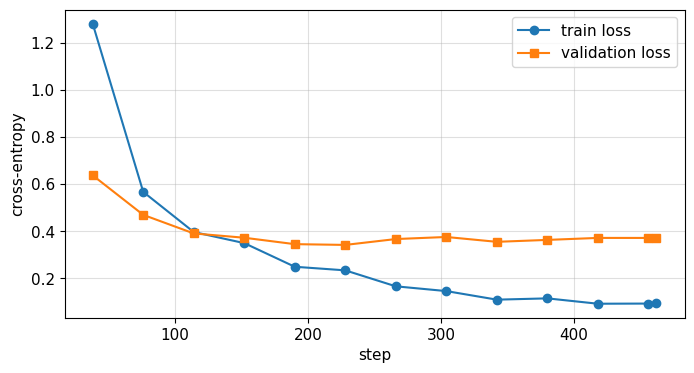

In [24]:
set_seed(SEED)
model = make_model()
history, train_seconds = train_ner(model, tokenized['train'], tokenized['validation'])
RUN_TIMES['train_main_sec'] = train_seconds
train_curve = [(h['step'], h['loss']) for h in history if 'loss' in h]
eval_curve = [(h['step'], h['eval_loss']) for h in history if 'eval_loss' in h]
assert len(train_curve) >= 2 and len(eval_curve) >= 2, 'логируйте train и eval loss по ходу обучения'
print(f'обучение: {train_seconds:.1f} c на {DEVICE_NAME}, {len(tokenized["train"])} предложений, {EPOCHS} эпох(а)')

plt.figure(figsize=(8, 4))
plt.plot(*zip(*train_curve), 'o-', label='train loss')
plt.plot(*zip(*eval_curve), 's-', label='validation loss')
plt.xlabel('step')
plt.ylabel('cross-entropy')
plt.legend()
plt.grid(True, alpha=0.4)
plt.show()

**Вопрос.** Почему выбраны такие гиперпараметры? Что видно на кривых: есть ли переобучение, нужно ли больше эпох? Сколько заняло обучение и на каком устройстве?

**Ответ:**

Для rubert-tiny2 выбраны learning rate 0.0002, batch size 32 и 6 эпох. Маленькой модели задан больший learning rate, чем base-энкодеру в бонусе. Используются AdamW, weight decay 0.01 для матриц весов, warmup на 10% шагов, косинусное уменьшение learning rate и ограничение нормы градиента 1.0. На T4 обучение выполняется с fp16; MAX_LENGTH = 256 позволяет сохранить длинные обучающие примеры.

Train loss изменился с 1.2809 до 0.0964, validation loss — с 0.6372 до 0.3716. Минимальный validation loss составил 0.3420, затем он увеличивался при дальнейшем снижении train loss, что указывает на переобучение. Веса выбраны по максимальному промежуточному validation F1 (fp16) 0.7858 на шаге 380 из 462; при равном F1 сравнивался validation loss. Итоговые метрики в 4.2 посчитаны без fp16, поэтому могут немного отличаться от промежуточной оценки. Дальнейшее увеличение числа эпох без дополнительной проверки не обосновано.

Обучение вместе с промежуточной проверкой заняло 34.7 с на Tesla T4. По ходу обучения выполнено 13 оценок validation loss.

## 4.2 Метрики (3 балла)

1. Посчитайте на validation и test отчет `seqeval` по типам (P/R/F1, support), micro и macro F1
2. Реализуйте `token_f1(gold, pred)` - micro-F1 по словам: верное срабатывание - слово, у которого предсказанный тег не `O` и совпадает с истинным; тег `O` в precision и recall не участвует; если не-`O` слов нет ни в gold, ни в pred, функция возвращает 0.0
3. Сравните токенный F1 и F1 по сущностям и объясните разницу

In [25]:
def token_f1(gold, pred):
    if len(gold) != len(pred):
        raise ValueError('Число последовательностей различается')
    correct = predicted = actual = 0
    for gold_tags, pred_tags in zip(gold, pred):
        if len(gold_tags) != len(pred_tags):
            raise ValueError('Длины последовательностей различаются')
        for gold_tag, pred_tag in zip(gold_tags, pred_tags):
            correct += gold_tag == pred_tag and gold_tag != 'O'
            predicted += pred_tag != 'O'
            actual += gold_tag != 'O'
    return 2 * correct / (predicted + actual) if predicted + actual else 0.0

In [26]:
g, p = [['B-PER', 'I-PER', 'O', 'B-LOC']], [['B-PER', 'O', 'O', 'B-LOC']]
assert abs(token_f1(g, p) - 0.8) < 1e-9                       # 2 верных слова из 2 предсказанных и 3 истинных
assert abs(f1_score(g, p) - 0.5) < 1e-9                       # а по сущностям верна одна из двух
assert token_f1([['O', 'O']], [['O', 'O']]) == 0.0 and token_f1(g, g) == 1.0

def full_scores(gold, pred):
    result = entity_scores(gold, pred)
    report = classification_report(gold, pred, output_dict=True, zero_division=0)
    result['token_f1'] = token_f1(gold, pred)
    result['per_type'] = {name: report.get(name, {}) for name in ENTITY_TYPES}
    return result


val_pred = predict_word_tags(model, val_tokens)
validation = full_scores(val_gold, val_pred)
test_tokens = [list(words) for words in data['test']['tokens']]
test_gold = [[LABEL_NAMES[i] for i in tags] for tags in data['test']['ner_tags']]
test_pred = predict_word_tags(model, test_tokens)
final = full_scores(test_gold, test_pred)

for name, gold_tags, pred_tags, scores in [
    ('validation', val_gold, val_pred, validation),
    ('test', test_gold, test_pred, final),
]:
    print(name)
    print(classification_report(gold_tags, pred_tags, digits=4, zero_division=0))
    print(f'F1 micro: {scores["f1_micro"]:.4f}, F1 macro: {scores["f1_macro"]:.4f}, '
          f'token F1: {scores["token_f1"]:.4f}')

validation
              precision    recall  f1-score   support

     DISEASE     0.5780    0.5339    0.5551       118
        RISK     0.4405    0.5362    0.4837       207
     SYMPTOM     0.8203    0.8619    0.8406      1673

   micro avg     0.7626    0.8088    0.7850      1998
   macro avg     0.6129    0.6440    0.6264      1998
weighted avg     0.7666    0.8088    0.7867      1998

F1 micro: 0.7850, F1 macro: 0.6264, token F1: 0.8537
test
              precision    recall  f1-score   support

     DISEASE     0.4914    0.5375    0.5134       160
        RISK     0.1498    0.2331    0.1824       133
     SYMPTOM     0.7845    0.8136    0.7988      2242

   micro avg     0.7170    0.7657    0.7406      2535
   macro avg     0.4752    0.5280    0.4982      2535
weighted avg     0.7327    0.7657    0.7484      2535

F1 micro: 0.7406, F1 macro: 0.4982, token F1: 0.8286


**Вопрос.** Какой тип сущностей распознается хуже всего и почему (частота, длина спанов, разнообразие)? Чем отличаются micro и macro F1 в вашем случае? Чем отличаются токенный F1 и F1 по сущностям в ваших числах и за счет чего (какой выше и почему)? Какой из них ближе к тому, что нужно пользователю NER?

**Ответ:**

На validation получены micro-F1 0.7850 и macro-F1 0.6264, на test — 0.7406 и 0.4982. Хуже всего на test распознаётся RISK: F1 0.1824, support 133. Для RISK в train есть 752 сущности против 6724 SYMPTOM. На очищенном test средняя длина RISK составляет 2.53 токена, SYMPTOM — 2.20, DISEASE — 1.64. Более длинные и разнообразные упоминания анамнеза и факторов риска сложнее выделить с точными границами; при этом эти наблюдения не доказывают единственную причину различий.

Micro-F1 объединяет сущности всех типов, поэтому на него сильнее влияют многочисленные SYMPTOM. Macro-F1 усредняет F1 типов с одинаковым весом и заметнее реагирует на качество редких классов.

Токенный F1 на test равен 0.8286, F1 по сущностям — 0.7406. Токенная метрика засчитывает отдельные правильно размеченные слова, даже если весь спан восстановлен неточно. Для пользователя NER обычно важнее F1 по сущностям, потому что требуется целиком выделить нужный фрагмент и правильно определить его тип.

---
# 5. Анализ

## 5.1 Разбор ошибок (2 балла)

Аналог разбора ошибок детектора по IoU. Реализуйте `categorize_errors(gold_spans, pred_spans)`: каждый истинный спан получает ровно одну категорию, предсказанный спан, не пересекающийся ни с одним истинным, - категорию `spurious`. Возвращается список `(категория, истинный спан или None, предсказанный спан или None)`:

- `correct` - есть предсказанный спан с теми же границами и типом
- `boundary` - точного совпадения нет, но есть пересекающийся предсказанный спан того же типа (ошибка границы, аналог ошибки локализации)
- `type` - пересекающегося спана того же типа нет, но есть пересекающийся спан другого типа (ошибка типа, аналог ошибки класса)
- `missed` - ни один предсказанный спан не пересекается с истинным (пропуск)
- `spurious` - лишний спан (ложное срабатывание)

Посчитайте категории на validation, доли среди ошибок, покажите 5+ примеров ошибок разных категорий глазами (предложение, истинный и предсказанный спаны).

In [27]:
ERROR_CATEGORIES = ['correct', 'boundary', 'type', 'missed', 'spurious']


def categorize_errors(gold_spans, pred_spans):
    def overlap(a, b):
        return max(a[0], b[0]) < min(a[1], b[1])

    result = []
    for gold_span in gold_spans:
        if gold_span in pred_spans:
            result.append(('correct', gold_span, gold_span))
            continue
        candidates = [span for span in pred_spans if overlap(gold_span, span)]
        same_type = [span for span in candidates if span[2] == gold_span[2]]
        if same_type:
            category, candidates = 'boundary', same_type
        elif candidates:
            category = 'type'
        else:
            result.append(('missed', gold_span, None))
            continue
        best = max(candidates, key=lambda span: (
            min(span[1], gold_span[1]) - max(span[0], gold_span[0]),
            -abs(span[0] - gold_span[0]) - abs(span[1] - gold_span[1]),
        ))
        result.append((category, gold_span, best))
    for pred_span in pred_spans:
        if not any(overlap(gold_span, pred_span) for gold_span in gold_spans):
            result.append(('spurious', None, pred_span))
    return result

In [28]:
gold = [(0, 2, 'PER'), (4, 5, 'LOC'), (7, 9, 'ORG'), (11, 12, 'PER')]
pred = [(0, 2, 'PER'), (4, 6, 'LOC'), (7, 9, 'LOC'), (13, 14, 'ORG')]
res = categorize_errors(gold, pred)
assert collections.Counter(c for c, _, _ in res) == {'correct': 1, 'boundary': 1, 'type': 1, 'missed': 1, 'spurious': 1}
assert ('type', (7, 9, 'ORG'), (7, 9, 'LOC')) in res and ('spurious', None, (13, 14, 'ORG')) in res
assert ('boundary', (4, 5, 'LOC'), (4, 6, 'LOC')) in res and ('missed', (11, 12, 'PER'), None) in res
assert categorize_errors([], []) == [] and categorize_errors([], [(0, 1, 'PER')]) == [('spurious', None, (0, 1, 'PER'))]
assert [c for c, _, _ in categorize_errors([(0, 3, 'LOC')], [(1, 2, 'PER'), (2, 3, 'LOC')])] == ['boundary']
assert [c for c, _, _ in categorize_errors([(0, 2, 'LOC'), (2, 4, 'LOC')], [(0, 4, 'LOC')])] == ['boundary', 'boundary']
assert sorted(c for c, _, _ in categorize_errors([(0, 2, 'PER')], [(2, 3, 'PER')])) == ['missed', 'spurious']   # end не включается: спаны только соприкасаются

errors = dict.fromkeys(ERROR_CATEGORIES, 0)
error_examples = {name: [] for name in ERROR_CATEGORIES if name != 'correct'}
for i, (words, gold_tags, pred_tags) in enumerate(zip(val_tokens, val_gold, val_pred)):
    for category, gold_span, pred_span in categorize_errors(bio_to_spans(gold_tags), bio_to_spans(pred_tags)):
        errors[category] += 1
        if category != 'correct' and len(error_examples[category]) < 3:
            error_examples[category].append({
                'index': i, 'text': data['validation'][i]['text'],
                'gold': gold_span, 'pred': pred_span,
                'gold_text': ' '.join(words[gold_span[0]:gold_span[1]]) if gold_span else None,
                'pred_text': ' '.join(words[pred_span[0]:pred_span[1]]) if pred_span else None,
            })
n_errors = sum(value for key, value in errors.items() if key != 'correct')
print(f'{"category":<12}{"count":>9}{"error share":>14}')
for category, count in errors.items():
    share = '-' if category == 'correct' else f'{count / max(1, n_errors):.2%}'
    print(f'{category:<12}{count:>9}{share:>14}')
for category, examples in error_examples.items():
    for example in examples[:2]:
        print(f'\n{category}: {example["text"]}')
        print('gold:', example['gold'], example['gold_text'])
        print('pred:', example['pred'], example['pred_text'])

category        count   error share
correct          1616             -
boundary          244        46.21%
type               81        15.34%
missed             57        10.80%
spurious          146        27.65%

boundary: кашель сухой температура
gold: (0, 2, 'SYMPTOM') кашель сухой
pred: (0, 1, 'SYMPTOM') кашель

boundary: кашель сухой температура
gold: (2, 3, 'SYMPTOM') температура
pred: (1, 3, 'SYMPTOM') сухой температура

type: нарушение сна, усталось, потеря удовольствия, загруженность, резкое повышение масса тела, резкая смена настроения, подавленность
gold: (8, 9, 'RISK') загруженность
pred: (8, 9, 'SYMPTOM') загруженность

type: Дочке давала Эргоферон, сама чёт денег пожалела на себя: ) в итоге сейчас с ангиной сижу вот, у доченьки только легкий насморк остался!
gold: (16, 17, 'DISEASE') ангиной
pred: (16, 17, 'RISK') ангиной

missed: нарушение режима сна, чрезмерная продолжительность сна, чрезмерное спокойствие, нечувствительность к стрессу, мышечные спазмы или тики, слаб

**Вопрос.** Какая категория ошибок самая частая? Что общего у примеров в каждой категории? Какие ошибки - на самом деле ошибки разметки, а не модели? Что бы вы сделали, чтобы уменьшить самую частую категорию?

**Ответ:**

На validation чаще всего встречается категория boundary: 244 случаев, или 46.21% от всех ошибок. Всего получено 244 ошибок границ, 81 ошибок типа, 57 пропусков и 146 лишних сущностей; полностью совпало 1616 спанов.

В примере «кашель сухой температура» модель выделяет «кашель» вместо «кашель сухой» и присоединяет слово «сухой» к температуре. Это показывает проблему соседних симптомов без пунктуации. Среди ошибок типа «загруженность» предсказана как SYMPTOM вместо RISK, а «ангиной» — как RISK вместо DISEASE. Среди пропусков есть «психостимуляторы» и «отдает в копчик»: отдельные упоминания теряются в длинном перечислении. Лишние отдельные «частая» и «частые» также указывают на неверное отделение зависимых слов от симптома.

В «Признаки гипертрофии ПЖ» модель выделяет DISEASE, которого нет в эталоне: это кандидат на проверку пропуска в разметке. Однако без инструкции и экспертного решения нельзя уверенно назвать его ошибкой разметчика. Для уменьшения ошибок границ нужны согласованные правила включения зависимых слов и больше примеров соседних симптомов с пунктуацией и без неё.

## 5.2 Абляция (1 балл)

Один дополнительный эксперимент на выбор, все остальное как в 4.1:

- `'freeze'` - замороженный энкодер (учится только голова) vs полное дообучение. Сравните F1, время и число обучаемых параметров
- `'all_subwords'` - метка на все сабворды (`data.map(tokenize_and_align, batched=True, remove_columns=data['train'].column_names, fn_kwargs=dict(label_all_subwords=True))`) vs только на первый. Оценка по-прежнему по словам через `predict_word_tags`

Результат положите в `ablation` - словарь с настройкой и метриками обоих вариантов.

In [29]:
ABLATION = 'freeze'
model.cpu()
if device.type == 'cuda':
    torch.cuda.empty_cache()
set_seed(SEED)
frozen_model = make_model()
frozen_history, frozen_seconds = train_ner(
    frozen_model, tokenized['train'], tokenized['validation'],
    freeze_encoder=True, out_dir='runs/freeze')
frozen_pred = predict_word_tags(frozen_model, val_tokens)
ablation = {
    'setting': ABLATION,
    'full': {**full_scores(val_gold, val_pred), 'seconds': train_seconds,
             'trainable_params': model.training_summary['trainable_params']},
    'freeze': {**full_scores(val_gold, frozen_pred), 'seconds': frozen_seconds,
               'trainable_params': frozen_model.training_summary['trainable_params']},
}
print(f'{"setting":<12}{"F1 micro":>12}{"seconds":>12}{"trainable":>14}')
for name in ['full', 'freeze']:
    result = ablation[name]
    print(f'{name:<12}{result["f1_micro"]:>12.4f}{result["seconds"]:>12.1f}{result["trainable_params"]:>14,}')
frozen_model.cpu()
del frozen_model
if device.type == 'cuda':
    torch.cuda.empty_cache()

Loading weights:   0%|          | 0/53 [00:00<?, ?it/s]

step   38/462 | train loss: 1.8458 | val loss: 1.6474 | val F1: 0.1097
step   76/462 | train loss: 1.4162 | val loss: 1.1950 | val F1: 0.2916
step  114/462 | train loss: 1.0870 | val loss: 0.9724 | val F1: 0.4169
step  152/462 | train loss: 0.9261 | val loss: 0.8561 | val F1: 0.5136
step  190/462 | train loss: 0.8345 | val loss: 0.7893 | val F1: 0.5241
step  228/462 | train loss: 0.7826 | val loss: 0.7504 | val F1: 0.5436
step  266/462 | train loss: 0.7554 | val loss: 0.7259 | val F1: 0.5445
step  304/462 | train loss: 0.7330 | val loss: 0.7103 | val F1: 0.5487
step  342/462 | train loss: 0.7147 | val loss: 0.7013 | val F1: 0.5506
step  380/462 | train loss: 0.7078 | val loss: 0.6965 | val F1: 0.5531
step  418/462 | train loss: 0.7001 | val loss: 0.6948 | val F1: 0.5555
step  456/462 | train loss: 0.7237 | val loss: 0.6944 | val F1: 0.5555
step  462/462 | train loss: 0.6969 | val loss: 0.6944 | val F1: 0.5555
setting         F1 micro     seconds     trainable
full              0.7850  

**Вопрос.** Насколько изменилась метрика и время? Чем вы объясняете результат? Что бы вы проверили следующим шагом, чтобы вывод был надежнее?

**Ответ:**

При полном дообучении validation micro-F1 равен 0.7850, при замороженном энкодере — 0.5555; изменение составляет -0.2296. Время изменилось с 34.7 до 10.8 с, число обучаемых параметров — с 29,098,303 до 2,191.

При заморозке обучается только классификатор, а признаки энкодера не адаптируются к медицинским текстам. Разбиение, seed, число эпох, batch size и learning rate сохранены; в обоих вариантах выбраны веса по максимальному validation F1. Для более надёжного вывода нужны несколько seed и отдельный подбор learning rate для замороженной головы.

## 5.3 Выводы (1 балл)

5-8 предложений с числами: что сработало, что нет, главные ограничения (данные, разметка, модель, бюджет), что бы вы сделали дальше.

**Ответ:**

Дообучение rubert-tiny2 повысило validation micro-F1 со словарных 0.5404 до 0.7850, тогда как случайная голова получила 0.0460. На очищенном test micro-F1 составил 0.7406, macro-F1 — 0.4982. Токенный F1 0.8286 отражает качество отдельных меток, а точное извлечение сущностей дополнительно требует правильных границ. Обучение заняло 34.7 с на Tesla T4, лучшее состояние выбрано по validation F1. При заморозке энкодера validation F1 составил 0.5555. Самая частая категория ошибок — boundary, 244 случаев. Основные ограничения — небольшой датасет, дисбаланс типов, неоднозначность разметки, исключение четырёх проблемных тестовых записей и оценка по одному seed. Дальше проверить спорную разметку, запустить с разными seed и подборать гиперпараметров только на validation.

### Сохранение результатов

Ячейка сохраняет `artifacts/metrics.json`. Выполняется и в `FAST_MODE` для проверки формата, при финальном прогоне перезаписывается с `fast_mode: false`. Сдайте файл вместе с ноутбуком.

In [30]:
def json_ready(value):
    if isinstance(value, torch.Tensor):
        return json_ready(value.detach().cpu().tolist())
    if isinstance(value, np.ndarray):
        return json_ready(value.tolist())
    if isinstance(value, dict):
        return {str(k): json_ready(v) for k, v in value.items()}
    if isinstance(value, (tuple, list)):
        return [json_ready(v) for v in value]
    if isinstance(value, (float, np.floating)):
        return float(value) if math.isfinite(value) else None
    if isinstance(value, np.integer):
        return int(value)
    if isinstance(value, Path):
        return value.as_posix()
    return value


metrics = dict(
    track='nlp', model=MODEL_ID, revision=REVISION,
    dataset=f'{DATASET_ID}/{DATASET_CONFIG}' if DATASET_CONFIG else str(DATASET_ID), classes=ENTITY_TYPES,
    n_train=len(data['train']), n_val=len(data['validation']), n_test=len(data['test']),
    params_total=sum(p.numel() for p in model.parameters()),
    baseline=baseline, final=final, ablation=ablation, errors=errors,
    device=DEVICE_NAME, train_time_sec=RUN_TIMES.get('train_main_sec'), fast_mode=FAST_MODE)
for key in ['f1_micro', 'f1_macro', 'precision', 'recall', 'token_f1', 'per_type']:
    assert key in final, f'в final нет {key}'
(ARTIFACTS / 'metrics.json').write_text(json.dumps(json_ready(metrics), ensure_ascii=False, indent=2), encoding='utf-8')
print(json.dumps(json_ready({k: v for k, v in metrics.items() if k not in ('final', 'baseline')}), ensure_ascii=False)[:600])
print('final F1 micro', round(final['f1_micro'], 4))

{"track": "nlp", "model": "cointegrated/rubert-tiny2", "revision": "e8ed3b0c8bbf4fb6984c3de043bf7d2f4e5969ae", "dataset": "medlinx/RuClinNER/medterm", "classes": ["DISEASE", "RISK", "SYMPTOM"], "n_train": 2439, "n_val": 610, "n_test": 1421, "params_total": 29098303, "ablation": {"setting": "freeze", "full": {"f1_micro": 0.7850376487733786, "f1_macro": 0.6264324906789475, "precision": 0.7626238791882963, "recall": 0.8088088088088088, "token_f1": 0.8536967796405741, "per_type": {"DISEASE": {"precision": 0.5779816513761468, "recall": 0.5338983050847458, "f1-score": 0.5550660792951543, "support": 
final F1 micro 0.7406


---
# 6\*. Бонусные задачи

Включаются через `BONUS_TASKS`, за бонусы суммарно - до 4 баллов из 5.5 предложенных.

## 6.1 Доразметка (1.5 балла)

Разметьте сами 50+ новых предложений (Label Studio, doccano или вручную в JSON): например, тексты из другого источника или трудные случаи из 5.1. Опишите инструкцию разметки, приведите разметку к контракту из 2.1, добавьте в train (или сделайте отдельный test) и покажите, как изменилась метрика. Файл с разметкой приложите к сдаче.

In [ ]:
if '6.1' in BONUS_TASKS:
    # ваш код
    pass

**Вопрос.** Сколько и каких примеров вы разметили, сколько времени заняла разметка, как изменилась метрика и на каком сплите? Где вы сами сомневались в разметке?

**Ответ:**

Бонус 6.1 не выполнялся. Выбраны бонусы 6.2–6.5.

## 6.2 Другая модель (1 балл)

Сравните с другим энкодером (многоязычный vs одноязычный, base vs маленький) при том же протоколе - или zero-shot NER открытой LLM с Hugging Face против дообученного энкодера. Сравните F1, время обучения и инференса, размер.

In [32]:
if '6.2' in BONUS_TASKS:
    OTHER_MODEL_ID = 'ai-forever/ruBert-base'
    OTHER_REVISION = '05f37a2ca9e333fd18f30cd0c96c68d274793c69'
    other_tokenizer = AutoTokenizer.from_pretrained(OTHER_MODEL_ID, revision=OTHER_REVISION)
    assert other_tokenizer.is_fast
    other_tokenized = data.map(tokenize_and_align, batched=True,
                               remove_columns=data['train'].column_names,
                               fn_kwargs={'tok': other_tokenizer})
    model.cpu()
    if device.type == 'cuda':
        torch.cuda.empty_cache()
    set_seed(SEED)
    other_model = make_model(OTHER_MODEL_ID, OTHER_REVISION)
    other_history, other_seconds = train_ner(
        other_model, other_tokenized['train'], other_tokenized['validation'],
        lr=3e-5, tok=other_tokenizer, out_dir='runs/other')
    other_pred = predict_word_tags(other_model, val_tokens, tok=other_tokenizer)

    def measure_latency(current_model, current_tokenizer):
        current_model.eval().to(device)
        batch = current_tokenizer(val_tokens[:32], is_split_into_words=True,
                                  truncation=True, padding='max_length', max_length=128,
                                  return_tensors='pt').to(device)
        with torch.inference_mode():
            for _ in range(5):
                current_model(**batch)
            if device.type == 'cuda':
                torch.cuda.synchronize()
            start = time.perf_counter()
            for _ in range(20):
                current_model(**batch)
            if device.type == 'cuda':
                torch.cuda.synchronize()
        return (time.perf_counter() - start) * 1000 / 20

    other_latency = measure_latency(other_model, other_tokenizer)
    other_result = {
        **full_scores(val_gold, other_pred), 'seconds': other_seconds,
        'params': sum(p.numel() for p in other_model.parameters()),
        'size_mb': sum(p.numel() * p.element_size() for p in other_model.parameters()) / 2**20,
        'latency_ms': other_latency, 'peak_gpu_mb': other_model.training_summary['peak_gpu_mb'],
    }
    other_model.cpu()
    main_latency = measure_latency(model, tokenizer)
    bonus62 = {
        'model_id': OTHER_MODEL_ID, 'revision': OTHER_REVISION, 'license': 'apache-2.0',
        'main': {**validation, 'seconds': train_seconds,
                 'params': sum(p.numel() for p in model.parameters()),
                 'size_mb': sum(p.numel() * p.element_size() for p in model.parameters()) / 2**20,
                 'latency_ms': main_latency, 'peak_gpu_mb': model.training_summary['peak_gpu_mb']},
        'other': other_result,
    }
    print('revision:', OTHER_REVISION)
    print(f'{"model":<18}{"val F1":>10}{"seconds":>11}{"params":>14}{"MB":>10}{"forward ms":>13}')
    for name, result in [('rubert-tiny2', bonus62['main']), ('ruBert-base', bonus62['other'])]:
        print(f'{name:<18}{result["f1_micro"]:>10.4f}{result["seconds"]:>11.1f}'
              f'{result["params"]:>14,}{result["size_mb"]:>10.1f}{result["latency_ms"]:>13.2f}')
    del other_model
    if device.type == 'cuda':
        torch.cuda.empty_cache()

Map:   0%|          | 0/2439 [00:00<?, ? examples/s]

Map:   0%|          | 0/610 [00:00<?, ? examples/s]

Map:   0%|          | 0/1421 [00:00<?, ? examples/s]

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

step   38/462 | train loss: 1.2387 | val loss: 0.5639 | val F1: 0.7075
step   76/462 | train loss: 0.5010 | val loss: 0.4125 | val F1: 0.7509
step  114/462 | train loss: 0.3410 | val loss: 0.3310 | val F1: 0.7914
step  152/462 | train loss: 0.2835 | val loss: 0.2927 | val F1: 0.8173
step  190/462 | train loss: 0.1962 | val loss: 0.2874 | val F1: 0.8255
step  228/462 | train loss: 0.1799 | val loss: 0.2772 | val F1: 0.8352
step  266/462 | train loss: 0.1162 | val loss: 0.3129 | val F1: 0.8356
step  304/462 | train loss: 0.1100 | val loss: 0.3029 | val F1: 0.8375
step  342/462 | train loss: 0.0774 | val loss: 0.3099 | val F1: 0.8345
step  380/462 | train loss: 0.0787 | val loss: 0.3094 | val F1: 0.8395
step  418/462 | train loss: 0.0658 | val loss: 0.3154 | val F1: 0.8392
step  456/462 | train loss: 0.0587 | val loss: 0.3166 | val F1: 0.8389
step  462/462 | train loss: 0.0703 | val loss: 0.3166 | val F1: 0.8389
revision: 05f37a2ca9e333fd18f30cd0c96c68d274793c69
model                 val 

**Вопрос.** Что лучше и какой ценой (время, память)? Как вы обеспечили честность сравнения?

**Ответ:**

Сравнены rubert-tiny2 и ai-forever/ruBert-base (Apache 2.0, ревизия 05f37a2ca9e333fd18f30cd0c96c68d274793c69). На validation micro-F1 составил 0.7850 и 0.8397, время обучения — 34.7 и 100.7 с. Число параметров равно 29,098,303 и 177,722,119, объём параметров float32 — 111.0 и 678.0 МБ.

Прямой проход батча 32 × 128 на одном устройстве после прогрева в среднем занял 11.31 и 262.61 мс. Это время модели без токенизации. Пиковый объём памяти, выделенной PyTorch на GPU во время обучения, составил 1317.9 и 5080.7 МБ. Base-модель получила более высокий F1, но потребовала больше времени и памяти; tiny подходит при более строгих ограничениях ресурсов.

Использованы одинаковые тексты, разбиение, seed, 6 эпох, batch size, MAX_LENGTH и правило выбора весов по validation F1. У каждой модели свой токенизатор; learning rate равен 2e-4 для tiny и 3e-5 для base. Это сравнение практических настроек двух моделей, а не эксперимент с полностью одинаковыми гиперпараметрами или одинаковым вычислительным бюджетом.

## 6.3 Устойчивость к сдвигу (1 балл)

Испортите validation и посмотрите на F1: опечатки, весь текст в нижнем или верхнем регистре, транслит, или другой домен (новости, соцсети, другой датасет с теми же типами). Метки при порче не меняются.

In [33]:
if '6.3' in BONUS_TASKS:
    typo_rng = random.Random(SEED)

    def add_typo(word):
        if len(word) < 4 or not word.isalpha() or typo_rng.random() >= 0.3:
            return word
        positions = [i for i in range(len(word) - 1) if word[i] != word[i + 1]]
        if not positions:
            return word
        i = typo_rng.choice(positions)
        return word[:i] + word[i + 1] + word[i] + word[i + 2:]

    variants = {
        'lower': [[word.lower() for word in words] for words in val_tokens],
        'upper': [[word.upper() for word in words] for words in val_tokens],
        'typos': [[add_typo(word) for word in words] for words in val_tokens],
    }
    bonus63 = {'clean': validation}
    for name, words_list in variants.items():
        assert all(len(a) == len(b) for a, b in zip(val_tokens, words_list))
        pred = predict_word_tags(model, words_list)
        result = full_scores(val_gold, pred)
        result['changed_words'] = sum(a != b for ws, vs in zip(val_tokens, words_list) for a, b in zip(ws, vs))
        result['subwords'] = sum(len(tokenizer(ws, is_split_into_words=True)['input_ids']) - 2 for ws in words_list)
        bonus63[name] = result
    bonus63['clean_subwords'] = sum(len(tokenizer(ws, is_split_into_words=True)['input_ids']) - 2 for ws in val_tokens)
    print(f'{"variant":<12}{"F1 micro":>12}{"change":>12}{"changed words":>16}')
    for name in ['clean', 'lower', 'upper', 'typos']:
        result = bonus63[name]
        print(f'{name:<12}{result["f1_micro"]:>12.4f}'
              f'{result["f1_micro"] - validation["f1_micro"]:>12.4f}{result.get("changed_words", 0):>16}')
    print('subwords:', {name: bonus63[name]['subwords'] for name in variants})
    print('clean subwords:', bonus63['clean_subwords'])

variant         F1 micro      change   changed words
clean             0.7850      0.0000               0
lower             0.7782     -0.0069             361
upper             0.0060     -0.7791            6517
typos             0.6919     -0.0932            1506
subwords: {'lower': 11261, 'upper': 28009, 'typos': 13575}
clean subwords: 11345


**Вопрос.** Какая порча сильнее всего роняет F1 и почему (вспомните, как токенизатор режет слова и какие признаки сущности есть в тексте)?

**Ответ:**

На исходном validation micro-F1 равен 0.7850, после перевода в нижний регистр — 0.7782, в верхний — 0.0060, после опечаток — 0.6919. Самое низкое качество получено для upper: изменение относительно исходных текстов -0.7791.

В варианте typos в 30% подходящих слов случайно переставляются соседние разные буквы; фактически изменено 1506 слов. Число сабвордов изменилось с 11345 до 13575. Для upper число сабвордов равно 28009: регистр заметно меняет токенизацию этой модели. Изменения написания влияют на разбиение слов и привычные признаки, которые модель видела при обучении. Границы исходных слов и их метки сохранены, поэтому сравнивается устойчивость к выбранным искажениям, а не новая задача разметки.

## 6.4 Экспорт и скорость (1 балл)

Экспортируйте модель в ONNX (или примените `torch.compile` / квантизацию), замерьте задержку до и после на одном и том же батче и устройстве (с прогревом, среднее по 10+ запускам) и проверьте, что F1 не упал (или упал незначительно).

Для ONNX: `%pip install -q onnx onnxruntime onnxscript`.

In [34]:
if '6.4' in BONUS_TASKS:
    import io
    import platform

    model.cpu().eval()
    previous_threads = torch.get_num_threads()
    torch.set_num_threads(2)
    quantized_model = torch.ao.quantization.quantize_dynamic(
        copy.deepcopy(model), {torch.nn.Linear}, dtype=torch.qint8)
    cpu = torch.device('cpu')
    batch = tokenizer(val_tokens[:32], is_split_into_words=True, truncation=True,
                      padding='max_length', max_length=128, return_tensors='pt')

    timings = {'float32': [], 'int8': []}
    models = {'float32': model, 'int8': quantized_model}
    with torch.inference_mode():
        for current_model in models.values():
            for _ in range(5):
                current_model(**batch)
        for repeat in range(30):
            order = ['float32', 'int8'] if repeat % 2 == 0 else ['int8', 'float32']
            for name in order:
                start = time.perf_counter()
                models[name](**batch)
                timings[name].append((time.perf_counter() - start) * 1000)

    float_pred = predict_word_tags(model, val_tokens, dev=cpu)
    int8_pred = predict_word_tags(quantized_model, val_tokens, dev=cpu)

    def state_size_mb(current_model):
        buffer = io.BytesIO()
        torch.save(current_model.state_dict(), buffer)
        return buffer.tell() / 2**20

    bonus64 = {
        'device': platform.processor() or platform.machine(), 'threads': 2, 'batch_shape': list(batch['input_ids'].shape),
        'float32': {**full_scores(val_gold, float_pred), 'latency_ms': float(np.mean(timings['float32'])),
                    'std_ms': float(np.std(timings['float32'])), 'size_mb': state_size_mb(model)},
        'int8': {**full_scores(val_gold, int8_pred), 'latency_ms': float(np.mean(timings['int8'])),
                 'std_ms': float(np.std(timings['int8'])), 'size_mb': state_size_mb(quantized_model)},
    }
    bonus64['speedup'] = bonus64['float32']['latency_ms'] / bonus64['int8']['latency_ms']
    print(f'{"format":<12}{"val F1":>12}{"mean ms":>12}{"std ms":>12}{"size MB":>12}')
    for name in ['float32', 'int8']:
        result = bonus64[name]
        print(f'{name:<12}{result["f1_micro"]:>12.4f}{result["latency_ms"]:>12.2f}'
              f'{result["std_ms"]:>12.2f}{result["size_mb"]:>12.1f}')
    print(f'speedup: {bonus64["speedup"]:.2f}x, CPU, 2 threads, batch 32 x 128')
    del quantized_model
    torch.set_num_threads(previous_threads)

/tmp/ipykernel_4724/1309767359.py:8: DeprecationWarning: torch.ao.quantization is deprecated and will be removed in 2.10. 
For migrations of users: 
1. Eager mode quantization (torch.ao.quantization.quantize, torch.ao.quantization.quantize_dynamic), please migrate to use torchao eager mode quantize_ API instead 
2. FX graph mode quantization (torch.ao.quantization.quantize_fx.prepare_fx,torch.ao.quantization.quantize_fx.convert_fx, please migrate to use torchao pt2e quantization API instead (prepare_pt2e, convert_pt2e) 
3. pt2e quantization has been migrated to torchao (https://github.com/pytorch/ao/tree/main/torchao/quantization/pt2e) 
see https://github.com/pytorch/ao/issues/2259 for more details
  quantized_model = torch.ao.quantization.quantize_dynamic(
/usr/local/lib/python3.13/dist-packages/torch/ao/nn/quantized/modules/utils.py:72: UserWarning: torch.quantize_per_tensor, torch.quantize_per_channel and other quantized tensor creation functions that produce tensors with dtype torc

format            val F1     mean ms      std ms     size MB
float32           0.7850      267.02       83.09       111.0
int8              0.7847      239.42       76.60       104.5
speedup: 1.12x, CPU, 2 threads, batch 32 x 128


**Вопрос.** Какое ускорение и на каком устройстве? Изменилась ли метрика? Почему выигрыш зависит от модели (вспомните, где у вашей модели основная часть параметров и вычислений)?

**Ответ:**

Выполнена динамическая int8-квантизация линейных слоёв. На CPU с 2 потоками для одного батча 32 × 128 среднее время прямого прохода изменилось с 267.02 до 239.42 мс, отношение времён — 1.12×. Для каждого варианта выполнено 5 прогревочных и 30 измеряемых проходов, порядок измерений чередовался.

Validation micro-F1 изменился с 0.7850 до 0.7847 (-0.0004). Размер сериализованного state_dict изменился с 111.0 до 104.5 МБ.

Большая часть параметров rubert-tiny2 находится в эмбеддингах, которые в этом эксперименте не квантизуются. Поэтому размер уменьшается ограниченно, а ускорение определяется работой линейных слоёв, размером батча и накладными расходами квантизации. Эти измерения относятся к CPU и не переносятся напрямую на T4.

## 6.5 Порог уверенности спана (1 балл)

Уверенность спана - средняя (или минимальная) по словам спана вероятность предсказанного тега (`predict_word_tags(..., return_probs=True)`). Отбрасывая спаны ниже порога, постройте кривую precision-recall по сущностям на validation и найдите порог с лучшим F1.

mean {'threshold': 0.77, 'precision': 0.8643018018018018, 'recall': 0.7682682682682682, 'f1': 0.8134605193428723} delta F1: 0.028422870569493774
min {'threshold': 0.78, 'precision': 0.8990881458966565, 'recall': 0.7402402402402403, 'f1': 0.8119681581114466} delta F1: 0.026930509338068065


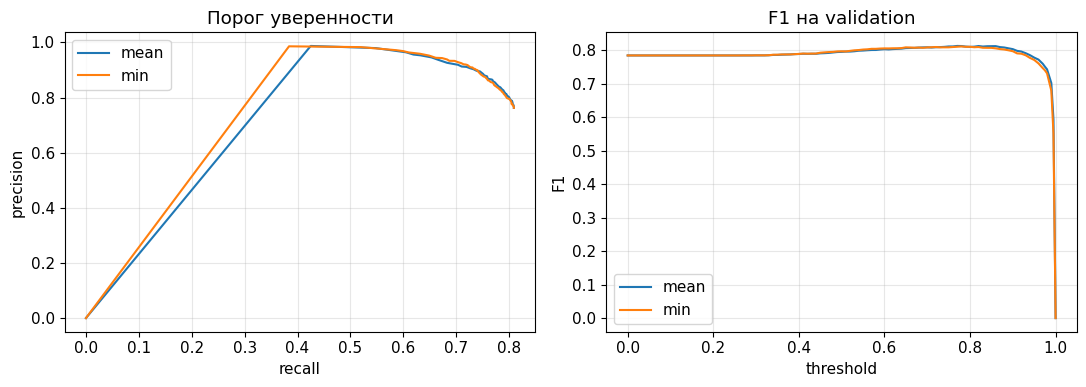

In [35]:
if '6.5' in BONUS_TASKS:
    threshold_tags, word_probs = predict_word_tags(model, val_tokens, return_probs=True)
    predicted_spans = [bio_to_spans(tags) for tags in threshold_tags]
    gold_spans = [set(bio_to_spans(tags)) for tags in val_gold]
    actual_count = sum(map(len, gold_spans))
    thresholds = np.unique(np.r_[np.linspace(0, 1, 101), 0.95, 0.975, 0.99, 0.995])
    threshold_results = {}

    for method in ['mean', 'min']:
        scored_spans = []
        for spans, probabilities in zip(predicted_spans, word_probs):
            scored_spans.append([
                (span, float(np.mean(probabilities[span[0]:span[1]]) if method == 'mean'
                             else np.min(probabilities[span[0]:span[1]])))
                for span in spans
            ])
        rows = []
        for threshold in thresholds:
            correct = predicted = 0
            for gold, candidates in zip(gold_spans, scored_spans):
                kept = {span for span, confidence in candidates if confidence >= threshold}
                correct += len(gold & kept)
                predicted += len(kept)
            precision = correct / predicted if predicted else 0.0
            recall = correct / actual_count if actual_count else 0.0
            f1 = 2 * correct / (predicted + actual_count) if predicted + actual_count else 0.0
            rows.append({'threshold': float(threshold), 'precision': precision, 'recall': recall, 'f1': f1})
        assert all(b['recall'] <= a['recall'] + 1e-12 for a, b in zip(rows, rows[1:]))
        assert abs(rows[0]['f1'] - validation['f1_micro']) < 1e-8
        threshold_results[method] = {'best': max(rows, key=lambda row: (row['f1'], -row['threshold'])),
                                     'rows': rows}

    bonus65 = threshold_results
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    for method, result in bonus65.items():
        rows = result['rows']
        axes[0].plot([row['recall'] for row in rows], [row['precision'] for row in rows], label=method)
        axes[1].plot([row['threshold'] for row in rows], [row['f1'] for row in rows], label=method)
        print(method, result['best'], 'delta F1:', result['best']['f1'] - validation['f1_micro'])
    axes[0].set(xlabel='recall', ylabel='precision', title='Порог уверенности')
    axes[1].set(xlabel='threshold', ylabel='F1', title='F1 на validation')
    for ax in axes:
        ax.legend()
        ax.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

**Вопрос.** Какой порог дает лучший F1 и сколько он добавляет к порогу 0? Чем отличаются средняя и минимальная уверенность? Почему порог по уверенности не может поднять recall?

**Ответ:**

Для средней уверенности лучший порог на validation равен 0.770: F1 0.8135, изменение относительно порога 0 составляет +0.0284. Для минимальной уверенности лучший порог равен 0.780: F1 0.8120, изменение +0.0269. При равном F1 выбирается меньший порог. Это подбор на validation, поэтому улучшение требует независимой проверки.

Средняя уверенность сглаживает отдельные неуверенные слова, минимальная определяется самым неуверенным словом спана и строже отбрасывает длинные сущности. Повышение порога только удаляет уже предсказанные спаны, поэтому число правильно найденных сущностей не увеличивается и recall не может вырасти. Precision при этом может как увеличиваться, так и уменьшаться в зависимости от того, какие спаны удаляются.

In [ ]:
bonus_results = {
    key: globals()[name] for key, name in [
        ('6.2', 'bonus62'), ('6.3', 'bonus63'),
        ('6.4', 'bonus64'), ('6.5', 'bonus65')
    ] if key in BONUS_TASKS
}
details = {
    'validation': validation, 'final': final, 'baseline': baseline,
    'history': history, 'training': model.training_summary,
    'train_seconds': train_seconds, 'device': DEVICE_NAME,
    'errors': errors, 'error_examples': error_examples, 'ablation': ablation,
    'bonuses': bonus_results, 'max_length': MAX_LENGTH, 'epochs': EPOCHS,
    'n_train': len(data['train']), 'n_val': len(data['validation']), 'n_test': len(data['test']),
    'conversion_stats': conversion_stats, 'rejected_examples': rejected_examples,
    'tokenization': {'checked': n_checked, 'at_limit': n_truncated, 'lost_words': n_lost_words},
}
metrics['validation'] = validation
metrics['bonuses'] = bonus_results
metrics['max_length'] = MAX_LENGTH
metrics['epochs'] = EPOCHS
(ARTIFACTS / 'metrics.json').write_text(json.dumps(json_ready(metrics), ensure_ascii=False, indent=2), encoding='utf-8')
(ARTIFACTS / 'experiment_details.json').write_text(json.dumps(json_ready(details), ensure_ascii=False, indent=2), encoding='utf-8')
import zipfile
with zipfile.ZipFile('hw2_artifacts.zip', 'w', zipfile.ZIP_DEFLATED) as archive:
    for name in ['metrics.json', 'experiment_details.json']:
        path = ARTIFACTS / name
        archive.write(path, path.as_posix())
print('Результаты сохранены: artifacts/metrics.json, artifacts/experiment_details.json')
from google.colab import files
files.download('hw2_artifacts.zip')
